<a href="https://colab.research.google.com/github/fxrdhan/ML_scikit-learn_Cookbook_O-Reilly/blob/main/Chapter_12_Cross_Validation_and_Model_Evaluation/Chapter_12_Cross_Validation_and_Model_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 12 — Cross-Validation and Model Evaluation Techniques

| | |
|---|---|
| **Book** | *scikit-learn Cookbook, Third Edition* — John Sukup (Packt Publishing, 2025) |
| **Library version targeted by the book** | scikit-learn 1.5 |
| **Version used to run this notebook** | scikit-learn 1.9.1 on Python 3.12 (printed by the setup cell) |
| **What this notebook contains** | reproduction of every code listing in the chapter and of the official exercise solutions, chapter and recipe summaries, theoretical deep-dives, and extra experiments |

## Chapter overview

Every model of the previous chapters was judged on data it had not seen, but a single split into a training and a test set gives one number, and one number is a noisy and wasteful answer. Chapter 12 is about **estimating how a model will perform on new data**, and about using that estimate to choose between models without fooling yourself. The chapter shows how to:

* estimate performance with **k-fold** and **stratified k-fold cross-validation**;
* use **leave-one-out** cross-validation and **nested** cross-validation;
* run cross-validation with `cross_val_score()`, `cross_validate()` and `GridSearchCV()`;
* choose hyperparameters with **grid search** and **randomized search**;
* diagnose generalization with **learning curves** and **validation curves**;
* practise with three exercises.

### Recipes in this chapter

| # | Recipe | Code in the book | What this notebook adds |
|---|---|---|---|
| 1 | Introduction to cross-validation | Yes, 2 listings | The book's two accuracies against 200 shuffles, the error bar of a CV estimate, how many folds, when stratification matters |
| 2 | Advanced cross-validation methods | Yes, 2 listings | Leave-one-out by hand, the selection bias that nested CV removes, split anatomy, leakage through groups and through time |
| 3 | Implementing cross-validation in scikit-learn | Yes, 2 listings | What `cv=5` really does, a baseline, a metrics overview (listed in the chapter introduction but absent from the book), `cross_val_predict`, leakage through preprocessing |
| 4 | Model selection techniques | Yes, 2 listings | Counting the fits of each search, reading `cv_results_`, the metric that picks the winner, random against grid under a budget, the winner's curse |
| 5 | Evaluating model generalizability | Yes, 2 listings | The numbers behind the two figures, high bias against high variance, a bias-variance simulation, why CV cannot see a shift in the data |
| 6 | Practical exercises in cross-validation and evaluation | Official solutions | Repeated CV, nested CV of the whole procedure, the error bar of a test accuracy, learning curves of two models |

### How to read this notebook

Every recipe has the same structure:

1. **Summary** — what the book says, condensed.
2. **Theory** — the ideas behind it: math, algorithms and design reasoning.
3. **Book code** — the listing reproduced from the book (page numbers refer to the printed edition), followed by an **output analysis**.
4. **Extra** — experiments written for this notebook to make the theory concrete. They are *not* part of the book.

Every code cell starts with a label comment: `# BOOK CODE` for a listing reproduced from the book, `# EXTRA` for code written for this notebook.

---
## 0. Setup

Every dataset in this chapter is generated by NumPy and scikit-learn (`make_classification`, `make_moons`) or ships with it (`load_diabetes`), so the notebook runs offline. The setup cell prints the library versions and defines the plotting style of the extra figures.

**A note on random numbers.** Unlike the previous chapter, every listing of this chapter passes an explicit `random_state` (or none is needed), so no listing depends on NumPy's global generator and the cells can be run in any order. The extras use their own generators (`np.random.default_rng(...)`) and pass `random_state` to every estimator that has one. The extras that need a *population* to measure the true performance of a model draw many datasets from one large `make_classification` sample, called the population below.

In [1]:
import platform
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn

print(f"Python       : {platform.python_version()}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"SciPy        : {scipy.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")

sk_version = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
assert sk_version >= (1, 5), "This notebook needs scikit-learn >= 1.5 -> pip install -U scikit-learn"

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# print warnings without the file path, so that the saved output does not depend on the machine
warnings.formatwarning = lambda message, category, filename, lineno, line=None: f"{category.__name__}: {message}\n"

# A quiet, colour-blind-safe style used by the extra figures in this notebook
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua (checked for colour-vision deficiency)
INK, INK_SOFT, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_SOFT, "axes.labelsize": 10,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK_SOFT,
    "figure.dpi": 110, "font.size": 10,
})

Python       : 3.12.3
scikit-learn : 1.9.1
NumPy        : 2.5.3
SciPy        : 1.18.1
pandas       : 3.0.6
Matplotlib   : 3.11.2


---
## 1. Introduction to cross-validation

*Book: pp. 314–316.*

### Summary

* **Intro and the note on k** — cross-validation is "a cornerstone technique" for estimating how a model will perform on unseen data: instead of one train-test split, the data is divided into several subsets and the model is trained and validated several times. The $k$ of k-fold is the number of folds, "used similarly in K-means clustering".
* **Getting ready** — `make_classification(n_samples=500, n_features=10, n_informative=8, n_redundant=2, n_classes=2, random_state=2024)`.
* **How to do it** — `KFold(n_splits=5, shuffle=True, random_state=2024)` and a loop that trains a `LogisticRegression()` on four folds and scores it on the fifth: *Average accuracy (KFold): 0.756*. The same loop with `StratifiedKFold` gives *0.766*. The book comments that stratified k-fold "actually elicits a slightly higher accuracy, which is good news since the methodology is designed to make each fold more representative".
* **How it works** — k-fold splits the data into $k$ equal parts, trains on $k-1$ and tests on the remaining one, $k$ times. With imbalanced classes the folds may not represent the class distribution; stratification preserves the share of each class in each fold, and "in most imbalanced cases, stratified k-fold yields more stable and fair evaluation results".
* **Hands-on exercises** — a 7-step workflow: choose a dataset, check the class balance, apply `KFold()` and `StratifiedKFold()`, train a model in each fold, evaluate, compare the consistency of the two strategies.

### Theory

**What is being estimated.** A model is a function $\hat f$ fitted on a training set $\mathcal{T}$. Its **generalization error** is the expected loss on a new observation drawn from the same distribution as the data,
$$\mathrm{Err}_{\mathcal{T}} = \mathbb{E}\big[\, L\big(Y, \hat f_{\mathcal{T}}(X)\big) \mid \mathcal{T} \,\big], \qquad \mathrm{Err} = \mathbb{E}_{\mathcal{T}}\, \mathrm{Err}_{\mathcal{T}}.$$
The error on the training set is an optimistic estimate of it, because the model was fitted to those very points. The simplest honest estimate is a **hold-out**: keep a part of the data aside. It is cheap, but it uses only part of the data for training *and* only part for testing, and its value changes with the split.

**k-fold cross-validation.** Split the $n$ observations at random into $k$ folds of about $n/k$ points. For each fold $j$, fit the model on the other $k-1$ folds and compute the loss on fold $j$. With $\kappa(i)$ the fold that contains observation $i$ and $\hat f^{-j}$ the model fitted without fold $j$, the estimate is
$$\widehat{\mathrm{Err}}_{\mathrm{CV}} = \frac{1}{n} \sum_{i=1}^{n} L\big(y_i,\ \hat f^{-\kappa(i)}(x_i)\big).$$
Every observation is used once for testing and $k-1$ times for training, and every prediction is made by a model that did not see that observation. scikit-learn reports the $k$ per-fold scores; their mean equals the formula above for a metric such as accuracy when the folds have the same size.

**What the estimate estimates, and how good it is.**

* *Bias.* Each model is trained on a fraction $(k-1)/k$ of the data, so it is slightly worse than the model fitted on all the data: the estimate is **pessimistic**, and more so for small $k$ and for models that still improve with more data (this is the learning curve of recipe 5). Kohavi (1995) found ten-fold stratified cross-validation to be the best compromise on real data sets.
* *Variance.* The test points are a finite sample: the standard error of an accuracy $\hat p$ measured on $m$ test points is $\sqrt{\hat p(1-\hat p)/m}$, about 0.019 for $m = 500$ and $\hat p = 0.76$. A second source is the training set itself: the models of two folds share a fraction $(k-2)/(k-1)$ of their training points, so the $k$ scores are **positively correlated**.
* *Consequence for the error bar.* Because of this correlation, the standard deviation of the $k$ fold scores divided by $\sqrt{k}$ **underestimates** the uncertainty, and Bengio and Grandvalet (2004) proved that **no unbiased estimator of the variance of k-fold cross-validation exists**. Varoquaux (2018) shows that on small samples the error bars of cross-validation are large. A difference of one or two points between two cross-validation scores is rarely meaningful.
* *Bates, Hastie and Tibshirani (2024)* add that cross-validation estimates the *average* error of the procedure over training sets, not the error of the particular model that was fitted on the data in hand.

**Choice of $k$.** $k = n$ (leave-one-out, recipe 2) has the least bias and the highest cost; $k = 2$ has a large pessimistic bias; $k = 5$ or $10$ is the usual compromise. The extras measure it.

**Shuffling and stratification.** `KFold` without `shuffle=True` cuts the data in the order of the rows, which is wrong if the rows are sorted (by class, by date, by subject). **Stratification** keeps the proportions of the classes in every fold. It matters when a class is rare or the sample is small: a fold without any positive makes recall undefined, and the share of positives in the test folds varies from fold to fold. For a balanced data set of 500 rows it changes almost nothing, which the extras show. **Repeated k-fold** (`RepeatedKFold`, `RepeatedStratifiedKFold`) averages over several random partitions and reduces the part of the variance that comes from the partition.

**Assessment and selection are two different jobs.** The estimate of this recipe *assesses* a model. If the same estimate is used to *choose* among many models or hyperparameters, the best score is optimistic; recipes 2 and 4 deal with it.

### Book code

The book's two listings: the data (p. 314) and the two cross-validation loops (p. 315). The loops use the `random_state=2024` of the splitters, so the printed numbers are reproducible.

In [2]:
# BOOK CODE (p. 314): load the libraries and generate the dataset
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Load the dataset
X, y = make_classification(n_samples=500, n_features=10, n_informative=8,
                           n_redundant=2, n_classes=2, random_state=2024)

In [3]:
# BOOK CODE (p. 315): k-fold and stratified k-fold cross-validation of a logistic regression
# Initialize the k-fold cross-validator
kf = KFold(n_splits=5, shuffle=True, random_state=2024)

# Iterate through the folds and evaluate
accuracies = []
for train_index, test_index in kf.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    model = LogisticRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracies.append(accuracy_score(y_test, y_pred))
print(f"Average accuracy (KFold): {np.mean(accuracies):.3f}")

# Use stratified k-fold for balanced class splits
strat_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)
strat_accuracies = []
for train_index, test_index in strat_kf.split(X, y):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    model = LogisticRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    strat_accuracies.append(accuracy_score(y_test, y_pred))
print(f"Average accuracy (StratifiedKFold): {np.mean(strat_accuracies):.3f}")

Average accuracy (KFold): 0.756
Average accuracy (StratifiedKFold): 0.766


**Output analysis.**

* The first listing prints nothing: it only builds the data, 500 samples with 10 features. `make_classification` has no class weights by default, so the two classes are **balanced (250 and 250)**.
* The second listing prints *Average accuracy (KFold): 0.756* and *Average accuracy (StratifiedKFold): 0.766*, the values of the book. The five fold accuracies are 0.72, 0.72, 0.88, 0.71 and 0.75 for `KFold` and 0.79, 0.76, 0.76, 0.76 and 0.76 for `StratifiedKFold` (extra (b)).
* The book reads the difference of 0.010 as a benefit of stratification. The extras show that it is not: the classes are balanced, and the difference comes from the random partition that each splitter draws with the same seed.

### Extra experiments

**(a) Is the stratified score really higher?** The book's two numbers come from one shuffle (`random_state=2024`). The cell repeats the comparison for **200 different shuffles**, with the same model and the same data, and also computes the repeated stratified k-fold (5 folds, 10 repeats) for 30 seeds. The figure compares the two distributions with the book's two values.

                         KFold (200 shuffles)  StratifiedKFold (200 shuffles)  RepeatedStratifiedKFold 5x10 (30 seeds)
mean of the CV accuracy                0.7700                          0.7709                                   0.7706
standard deviation                     0.0057                          0.0065                                   0.0021
minimum                                0.7540                          0.7540                                   0.7660
maximum                                0.7860                          0.7860                                   0.7756

stratified higher than plain k-fold for the same seed: 52.5% of the 200 seeds; mean difference +0.0009, standard deviation of the difference 0.0081
the book's KFold value 0.756 is lower than 1.0% of the 200 plain k-fold values; its StratifiedKFold value 0.766 is lower than 21.0% of the stratified ones


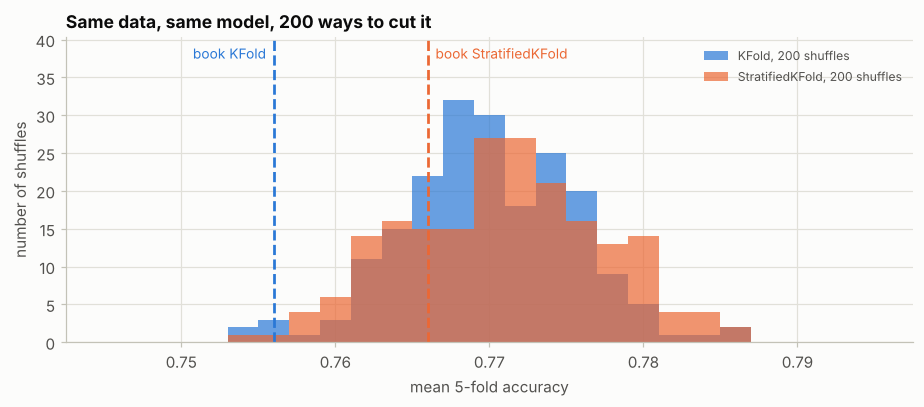

In [4]:
# EXTRA (a): the book's comparison of KFold and StratifiedKFold over 200 shuffles
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score


def mean_accuracy(cv):
    return cross_val_score(LogisticRegression(), X, y, cv=cv, scoring="accuracy").mean()


plain = np.array([mean_accuracy(KFold(5, shuffle=True, random_state=s)) for s in range(200)])
strat = np.array([mean_accuracy(StratifiedKFold(5, shuffle=True, random_state=s)) for s in range(200)])
repeated = np.array([mean_accuracy(RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=s)) for s in range(30)])

summary = pd.DataFrame({
    "KFold (200 shuffles)": [plain.mean(), plain.std(), plain.min(), plain.max()],
    "StratifiedKFold (200 shuffles)": [strat.mean(), strat.std(), strat.min(), strat.max()],
    "RepeatedStratifiedKFold 5x10 (30 seeds)": [repeated.mean(), repeated.std(), repeated.min(), repeated.max()],
}, index=["mean of the CV accuracy", "standard deviation", "minimum", "maximum"])
print(summary.round(4).to_string())
print(f"\nstratified higher than plain k-fold for the same seed: {(strat > plain).mean():.1%} of the 200 seeds; mean difference {(strat - plain).mean():+.4f}, standard deviation of the difference {(strat - plain).std():.4f}")
book_plain, book_strat = np.mean(accuracies), np.mean(strat_accuracies)
print(f"the book's KFold value {book_plain:.3f} is lower than {(plain < book_plain - 1e-9).mean():.1%} of the 200 plain k-fold values;"
      f" its StratifiedKFold value {book_strat:.3f} is lower than {(strat < book_strat - 1e-9).mean():.1%} of the stratified ones")

fig, ax = plt.subplots(figsize=(8.5, 3.8))
bins = np.linspace(0.745, 0.795, 26)
ax.hist(plain, bins=bins, color=PALETTE[0], alpha=0.7, label="KFold, 200 shuffles")
ax.hist(strat, bins=bins, color=PALETTE[1], alpha=0.7, label="StratifiedKFold, 200 shuffles")
ax.set_ylim(0, ax.get_ylim()[1] * 1.2)
ax.axvline(book_plain, color=PALETTE[0], ls="--", lw=1.8)
ax.axvline(book_strat, color=PALETTE[1], ls="--", lw=1.8)
ax.text(book_plain - 0.0005, ax.get_ylim()[1] * 0.93, "book KFold", color=PALETTE[0], ha="right", fontsize=9)
ax.text(book_strat + 0.0005, ax.get_ylim()[1] * 0.93, "book StratifiedKFold", color=PALETTE[1], ha="left", fontsize=9)
ax.set_xlabel("mean 5-fold accuracy")
ax.set_ylabel("number of shuffles")
ax.set_title("Same data, same model, 200 ways to cut it")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

**(b) The error bar of one cross-validation run.** The five fold accuracies of the book's two loops, their standard deviation, the naive standard error (that is, the standard deviation divided by $\sqrt{5}$), the binomial standard error of an accuracy measured on all 500 points, and the number of positive points in each test fold.

In [5]:
# EXTRA (b): fold scores, naive and binomial standard errors, class counts per fold
rows = []
for name, scores, splitter in [("KFold", accuracies, kf), ("StratifiedKFold", strat_accuracies, strat_kf)]:
    scores = np.asarray(scores)
    positives = [int(y[test].sum()) for _, test in splitter.split(X, y)]
    rows.append({
        "splitter": name, "fold accuracies": np.round(scores, 2).tolist(), "mean": scores.mean(), "sd of the folds": scores.std(ddof=1),
        "naive SE (sd / sqrt(5))": scores.std(ddof=1) / np.sqrt(5), "positives in the 5 test folds": positives,
    })
print(pd.DataFrame(rows).set_index("splitter").round(3).to_string())
p = np.mean(accuracies)
print(f"\nbinomial standard error of an accuracy of {p:.3f} measured on {len(y)} points: {np.sqrt(p * (1 - p) / len(y)):.3f}")
print(f"share of positives in the whole data: {y.mean():.3f}")

                                fold accuracies   mean  sd of the folds  naive SE (sd / sqrt(5)) positives in the 5 test folds
splitter                                                                                                                      
KFold            [0.72, 0.72, 0.88, 0.71, 0.75]  0.756            0.071                    0.032          [52, 47, 54, 51, 46]
StratifiedKFold  [0.79, 0.76, 0.76, 0.76, 0.76]  0.766            0.013                    0.006          [50, 50, 50, 50, 50]

binomial standard error of an accuracy of 0.756 measured on 500 points: 0.019
share of positives in the whole data: 0.500


**(c) How many folds?** A *population* of 40,000 points is generated once with the same recipe (`make_classification`, 10 features, 8 informative, 2 redundant). From it, 60 training sets of 100 points are drawn. For each one the true accuracy of the logistic regression fitted on the 100 points is measured on 20,000 other points of the population, and compared with the cross-validation estimate for $k$ = 2, 3, 5, 10, 20 and leave-one-out. The columns give the mean error of the estimate (bias), its standard deviation across the 60 training sets, the root mean squared error and the time of one cross-validation.

In [6]:
# EXTRA (c): bias, variance and cost of the CV estimate as a function of k, against a known truth
import time
from sklearn.model_selection import LeaveOneOut

POP_X, POP_y = make_classification(n_samples=40000, n_features=10, n_informative=8, n_redundant=2, n_classes=2, random_state=11)
n_train, n_sets = 100, 60
ks = [2, 3, 5, 10, 20, "LOO"]
estimates, seconds, truth = {k: [] for k in ks}, {k: 0.0 for k in ks}, []
for rep in range(n_sets):
    chosen = np.random.default_rng(rep).choice(len(POP_X), n_train, replace=False)
    rest = np.setdiff1d(np.arange(len(POP_X)), chosen)[:20000]
    X_small, y_small = POP_X[chosen], POP_y[chosen]
    truth.append(LogisticRegression().fit(X_small, y_small).score(POP_X[rest], POP_y[rest]))
    for k in ks:
        splitter = LeaveOneOut() if k == "LOO" else StratifiedKFold(k, shuffle=True, random_state=rep)
        start = time.perf_counter()
        estimates[k].append(cross_val_score(LogisticRegression(), X_small, y_small, cv=splitter).mean())
        seconds[k] += time.perf_counter() - start
truth = np.array(truth)
rows = []
for k in ks:
    est = np.array(estimates[k])
    paired = est - np.array(estimates["LOO"])                                    # same training set, so the noise of the test points cancels
    rows.append({
        "k": k, "mean estimate": est.mean(), "bias (estimate - truth)": (est - truth).mean(), "sd of the estimate": est.std(),
        "RMSE": np.sqrt(((est - truth) ** 2).mean()), "estimate minus leave-one-out (mean)": paired.mean(),
        "standard error of that difference": paired.std(ddof=1) / np.sqrt(n_sets), "time of one CV (s)": seconds[k] / n_sets,
    })
print(f"true accuracy of the model trained on {n_train} points: mean {truth.mean():.4f}, sd {truth.std():.4f} over the {n_sets} training sets\n")
frame = pd.DataFrame(rows).set_index("k")
print(frame.round(4).to_string())
print(f"\nbinomial standard error of an accuracy of {truth.mean():.2f} measured on {n_train} points: {np.sqrt(truth.mean() * (1 - truth.mean()) / n_train):.3f}")
print(f"correlation, over the {n_sets} training sets, between the 5-fold estimate and the true accuracy of that very model: {np.corrcoef(estimates[5], truth)[0, 1]:.2f}")

true accuracy of the model trained on 100 points: mean 0.7359, sd 0.0153 over the 60 training sets

     mean estimate  bias (estimate - truth)  sd of the estimate    RMSE  estimate minus leave-one-out (mean)  standard error of that difference  time of one CV (s)
k                                                                                                                                                                  
2           0.7242                  -0.0118              0.0482  0.0487                              -0.0123                             0.0056              0.0098
3           0.7333                  -0.0027              0.0471  0.0489                              -0.0032                             0.0037              0.0136
5           0.7400                   0.0041              0.0407  0.0410                               0.0035                             0.0026              0.0219
10          0.7403                   0.0044              0.0414  0.0437         

**(d) When stratification matters.** A small imbalanced sample: 100 points, 10 of them positive. The cell cuts it with `KFold` (5 folds) for 2,000 different shuffles and with `StratifiedKFold`, and counts the positives in each test fold (the expected number is 2).

In [7]:
# EXTRA (d): positives per test fold with and without stratification, on 100 points with 10 positives
y_rare = np.r_[np.ones(10, dtype=int), np.zeros(90, dtype=int)]
X_rare = np.zeros((100, 1))
counts = {"KFold": [], "StratifiedKFold": []}
folds_without_positive = {"KFold": 0, "StratifiedKFold": 0}
shuffles_with_empty_fold = {"KFold": 0, "StratifiedKFold": 0}
for seed in range(2000):
    for name, splitter in [("KFold", KFold(5, shuffle=True, random_state=seed)), ("StratifiedKFold", StratifiedKFold(5, shuffle=True, random_state=seed))]:
        per_fold = [int(y_rare[test].sum()) for _, test in splitter.split(X_rare, y_rare)]
        counts[name].extend(per_fold)
        folds_without_positive[name] += sum(c == 0 for c in per_fold)
        shuffles_with_empty_fold[name] += any(c == 0 for c in per_fold)
rows = []
for name in counts:
    c = np.array(counts[name])
    rows.append({
        "splitter": name, "min": c.min(), "max": c.max(), "sd of the count": c.std(),
        "test folds without any positive": f"{folds_without_positive[name] / len(c):.1%}", "shuffles with at least one such fold": f"{shuffles_with_empty_fold[name] / 2000:.1%}",
    })
print("positives in a test fold (expected: 2), 2,000 shuffles x 5 folds:")
print(pd.DataFrame(rows).set_index("splitter").round(3).to_string())

positives in a test fold (expected: 2), 2,000 shuffles x 5 folds:
                 min  max  sd of the count test folds without any positive shuffles with at least one such fold
splitter                                                                                                       
KFold              0    7            1.218                            9.9%                                45.3%
StratifiedKFold    2    2            0.000                            0.0%                                 0.0%


**Analysis of the extras.**

* **(a)** Over 200 shuffles the mean 5-fold accuracy is **0.7700 for `KFold` and 0.7709 for `StratifiedKFold`**, with a standard deviation of 0.0057 and 0.0065 from one shuffle to the next. The stratified score is higher than the plain one for 52.5% of the seeds (a coin flip), by +0.0009 on average. The book's seed happens to give its `KFold` value (0.756) lower than 1% of the plain values, and its `StratifiedKFold` value (0.766) lower than 21% of the stratified ones: the gap of 0.010 is about as large as the difference between two shuffles of the same splitter (that difference has a standard deviation of $\sqrt{2}$ times 0.0057 to 0.0065, that is 0.008 to 0.009; the difference between the two splitters, seed by seed, has a standard deviation of 0.0081). The repeated stratified 5-fold (5 folds, 10 repeats) has the same mean (0.7706) and a spread **about three times smaller** (0.0021).
* **(b)** The standard deviation of the five fold accuracies is 0.071 for the book's `KFold` and 0.013 for its `StratifiedKFold`, although the model and the data are the same: the dispersion of five numbers is itself very noisy. The naive standard error (the standard deviation divided by $\sqrt{5}$) is 0.032 and 0.006, whereas the binomial standard error of an accuracy of 0.756 measured on 500 points is **0.019**: the naive error bar of the stratified run underestimates the uncertainty by a factor of 3. On these balanced data the test folds of `KFold` hold 46 to 54 positives and those of `StratifiedKFold` exactly 50.
* **(c)** With a known truth (the model trained on 100 points has a true accuracy of 0.736), the only value of $k$ whose **pessimistic bias** stands out is $k = 2$: its estimate is 0.012 below the true accuracy and 0.0123 below the leave-one-out estimate of the same training sets (standard error 0.0056, about two standard errors). For $k \ge 3$ the difference from leave-one-out is at most 0.005. The estimates for $k$ = 5, 10 and 20 even lie 0.0035 to 0.0047 *above* leave-one-out (1.4 to 2.4 standard errors), the opposite of the ordering that the theory predicts for the bias; with 60 training sets this is most likely noise. The RMSE is 0.049 for $k$ = 2 and 3, **0.041 for $k = 5$**, 0.044 for 10 and 0.0425 for 20 and for leave-one-out: no number of folds above 5 reduces the error. The standard deviation of the estimates (0.040 to 0.048) is about the binomial standard error of an accuracy measured on 100 points (0.044): the finite test sample dominates. Leave-one-out needs 100 fits where 5 folds need 5, for no gain. The correlation between the 5-fold estimate and the true accuracy of the very model that was fitted is only **0.18**: cross-validation says more about the procedure than about the single model.
* **(d)** On 100 points with 10 positives, the test folds of `KFold` hold between **0 and 7** positives (2 expected); **9.9% of the test folds have no positive at all**, and 45.3% of the shuffles contain at least one such fold, for which recall is undefined. `StratifiedKFold` puts exactly 2 positives in every test fold.

---
## 2. Advanced cross-validation methods

*Book: pp. 316–318.*

### Summary

* **Intro** — two advanced techniques: **leave-one-out cross-validation (LOOCV)**, "useful when we want to make the most out of limited data", and **nested cross-validation**, which "helps us tune hyperparameters without data leakage between model selection and evaluation".
* **Getting ready** — `load_diabetes()` (the book says it has "10 features and a qualitative target variable representing disease progression") and `Ridge`, "which benefits from regularization tuning".
* **How to do it** — LOOCV of `Ridge(alpha=1.0)` with `scoring="neg_mean_squared_error"` (*LOOCV mean MSE: 3327.655*); a grid `alpha` in 0.01, 0.1, 1, 10, 100; nested cross-validation as `cross_val_score(GridSearchCV(Ridge(), param_grid, cv=5), X, y, cv=5)` (*Nested CV mean score: 0.480*). The book adds: "Using a randomized search instead of a grid search would be another alternative for hyperparameter tuning since our final 0.593 MSE is not much better than guessing."
* **How it works** — LOOCV trains on all points but one, repeats for every point, and gives "nearly unbiased estimates but at a higher computational cost". In nested cross-validation the inner loop selects the model and the outer loop evaluates it, "yielding a more honest estimate of generalization performance".
* **Hands-on exercises** — a 7-step workflow, ending with a comparison of the LOOCV and nested CV scores "to understand trade-offs in performance and computational cost".

### Theory

**Leave-one-out.** LOOCV is k-fold with $k = n$: $n$ fits, each tested on one point. Its estimate has the smallest pessimistic bias, because every model is trained on $n-1$ points, but it costs $n$ fits and it is not necessarily the most accurate: the $n$ training sets are almost identical, so the $n$ test errors are strongly correlated, and for unstable models the estimate can be noisier than a 10-fold one (Kohavi, 1995; Hastie, Tibshirani and Friedman, 2009, section 7.10). A single test point has a loss of 0 or 1 for accuracy, so only the *average* over all points is meaningful.

*A shortcut for linear smoothers.* When the fitted values are linear in the target, $\hat{y} = H y$ (least squares, ridge regression with a fixed penalty), the leave-one-out residual needs no refit:
$$y_i - \hat{y}_i^{(-i)} = \frac{y_i - \hat{y}_i}{1 - H_{ii}},$$
where $H$ is the hat matrix. This is the PRESS statistic, and it is what `RidgeCV` uses to choose its penalty. For a ridge regression with an unpenalized intercept, $H = \tfrac{1}{n}\mathbf{1}\mathbf{1}^\top + \tilde{X}(\tilde{X}^\top \tilde{X} + \alpha I)^{-1}\tilde{X}^\top$ with $\tilde{X}$ the centred features. The extras check it against the 442 fits of the book.

**Nested cross-validation: the problem it solves.** `GridSearchCV` returns `best_score_`, the *highest* mean cross-validation score among the candidates. Each candidate's score is a noisy estimate of its true performance, and the maximum of several noisy numbers is **biased upwards**: the more candidates and the smaller the sample, the larger the bias. Reporting `best_score_` as the performance of the chosen model is therefore optimistic (Varma and Simon, 2006; Cawley and Talbot, 2010). The estimate needs data that played no part in the selection.

**Nested cross-validation: the procedure.** An **outer** loop of $k_o$ folds assesses; inside each outer training part, an **inner** loop of $k_i$ folds runs the whole search and refits the winner, which is then scored on the outer test fold:

1. for each outer fold: take the outer training part;
2. run the grid search with inner cross-validation on it, and refit the best candidate on the whole outer training part;
3. score that model on the outer test fold, which the search never saw.

The mean of the outer scores estimates the performance of the **procedure** "search and fit" on data of that size, not of any single hyperparameter value (the winners may differ from fold to fold). The cost is $k_o \times (k_i \times |\text{grid}| + 1)$ fits; for the book's example $5 \times (5 \times 5 + 1) = 130$, against $5 \times 5 + 1 = 26$ for the search alone. Wainer and Cawley (2021) find that with few hyperparameters the extra cost often does not change the conclusion; the extras show the case where it does.

**The default score of a regressor is $R^2$.** `GridSearchCV` and `cross_val_score` use the `score` method of the estimator when `scoring` is not given: the accuracy for classifiers and the coefficient of determination
$$R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}$$
for regressors. So the book's "Nested CV mean score: 0.480" is an $R^2$, not a mean squared error, and it cannot be compared with the LOOCV value 3327.655, which is an MSE.

**Other splitters, and why they exist.** Cross-validation assumes that the rows are independent draws from one distribution. When they are not, a random split puts near-copies of the test points in the training set and the score is too optimistic.

| Splitter | What it does | Use it when |
|---|---|---|
| `KFold` | $k$ consecutive or shuffled folds | independent rows, regression (the default for regressors) |
| `StratifiedKFold` | folds with the class proportions of `y` | classification (the default for classifiers) |
| `RepeatedKFold`, `RepeatedStratifiedKFold` | k-fold repeated with different shuffles | small samples; reduces the noise due to the partition |
| `ShuffleSplit`, `StratifiedShuffleSplit` | random train/test splits that may overlap between splits | control of the train size; many splits |
| `LeaveOneOut`, `LeavePOut` | every sample, or every set of $p$ samples, is the test set | tiny samples; the cost of `LeavePOut` grows combinatorially |
| `GroupKFold`, `StratifiedGroupKFold`, `LeaveOneGroupOut` | all the rows of a group stay on the same side of the split | repeated measures on the same subject, site, patient |
| `TimeSeriesSplit` | train on the past, test on the future | ordered data |

Roberts et al. (2017) show, for grouped, spatial and temporal data, that random cross-validation can be far too optimistic. Bergmeir and Benítez (2012) and Cerqueira, Torgo and Mozetič (2020) compare cross-validation variants with out-of-sample evaluation for time series and recommend blocked splits, or a plain holdout when the series is not stationary. The extras reproduce the effect.

### Book code

The data (p. 317) and the two analyses (pp. 317–318). The outputs printed in the book are *LOOCV mean MSE: 3327.655* and *Nested CV mean score: 0.480*.

In [8]:
# BOOK CODE (p. 317): load the libraries and the diabetes data
# Load the libraries
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import LeaveOneOut, GridSearchCV, cross_val_score
from sklearn.linear_model import Ridge

# Load the dataset
data = load_diabetes()
X = data.data
y = data.target

In [9]:
# BOOK CODE (pp. 317-318): leave-one-out and nested cross-validation of a ridge regression
# Apply Leave-One-Out cross-validation with MSE scoring
loo = LeaveOneOut()
model = Ridge(alpha=1.0)
scores = cross_val_score(model, X, y, cv=loo, scoring="neg_mean_squared_error")
print(f"LOOCV mean MSE: {-np.mean(scores):.3f}")

# Define a grid for hyperparameter tuning
param_grid = {"alpha": [0.01, 0.1, 1, 10, 100]}

# Apply nested cross-validation using GridSearchCV (default scoring is fine for outer CV)
nested_scores = cross_val_score(
    GridSearchCV(Ridge(), param_grid, cv=5), X, y, cv=5
)
print(f"Nested CV mean score: {np.mean(nested_scores):.3f}")

LOOCV mean MSE: 3327.655
Nested CV mean score: 0.480


**Output analysis.**

* The data cell prints nothing. The listing prints *LOOCV mean MSE: 3327.655* (442 fits, one per sample) and *Nested CV mean score: 0.480*; the five outer scores are 0.411, 0.520, 0.492, 0.440 and 0.537.
* The two numbers are **not comparable**: the first is a mean squared error in squared units of the target, the second an $R^2$. The book's sentence "our final 0.593 MSE is not much better than guessing" refers to a number that appears nowhere in the code or in its output. Extra (b) shows that the nested mean squared error is 3004.9 against 5982.4 for a predictor that always answers the training mean: an $R^2$ of 0.48 means that about half of the variance is explained, which is far from guessing. The target is quantitative (from 25 to 346), not "qualitative" as the text says.

### Extra experiments

**(a) Leave-one-out without a loop.** The cell computes the hat matrix of the ridge regression, the leave-one-out residuals with the PRESS formula, and compares their mean square with the 442 fits of the book. It also asks `RidgeCV`, which uses the same shortcut, for the leave-one-out error of each `alpha` of the book's grid.

In [10]:
# EXTRA (a): the PRESS statistic against the 442 fits of the book
from sklearn.linear_model import RidgeCV

n_samples, n_features = X.shape
X_centred = X - X.mean(axis=0)
hat = np.ones((n_samples, n_samples)) / n_samples + X_centred @ np.linalg.inv(X_centred.T @ X_centred + 1.0 * np.eye(n_features)) @ X_centred.T
residual = y - hat @ y
loo_residual = residual / (1.0 - np.diag(hat))

print(f"the hat matrix reproduces the predictions of Ridge(alpha=1.0): {np.allclose(Ridge(alpha=1.0).fit(X, y).predict(X), hat @ y)}")
print(f"LOO mean squared error by the PRESS formula (1 fit) : {np.mean(loo_residual ** 2):.3f}")
print(f"LOO mean squared error of the book ({LeaveOneOut().get_n_splits(X)} fits): {-np.mean(scores):.3f}")

ridge_cv = RidgeCV(alphas=param_grid["alpha"], store_cv_results=True).fit(X, y)
loo_by_alpha = pd.Series(ridge_cv.cv_results_.mean(axis=0), index=param_grid["alpha"], name="LOO mean squared error (RidgeCV)")
print("\n" + loo_by_alpha.round(3).to_string())
print(f"\nRidgeCV picks alpha = {ridge_cv.alpha_}")

the hat matrix reproduces the predictions of Ridge(alpha=1.0): True
LOO mean squared error by the PRESS formula (1 fit) : 3327.655
LOO mean squared error of the book (442 fits): 3327.655

0.01      3000.392
0.10      3004.617
1.00      3327.655
10.00     4851.098
100.00    5794.725

RidgeCV picks alpha = 0.01


**(b) Nested against non-nested on the diabetes data.** The book's grid has 5 values and the sample has 442 rows. The cell compares the `best_score_` of the grid search (an $R^2$, as in the book) with the nested score, repeats the nested evaluation with the mean squared error so that it can be compared with the LOOCV value, and adds a baseline that always predicts the mean of the training target.

In [11]:
# EXTRA (b): non-nested and nested scores on the diabetes data, with a baseline
from sklearn.dummy import DummyRegressor

search = GridSearchCV(Ridge(), param_grid, cv=5).fit(X, y)
nested_mse = -cross_val_score(GridSearchCV(Ridge(), param_grid, cv=5, scoring="neg_mean_squared_error"), X, y, cv=5, scoring="neg_mean_squared_error")
dummy_mse = -cross_val_score(DummyRegressor(), X, y, cv=5, scoring="neg_mean_squared_error")
dummy_r2 = cross_val_score(DummyRegressor(), X, y, cv=5)

print(f"range of the target: {y.min():.0f} to {y.max():.0f}; variance {y.var():.1f}")
print(f"grid search alone : best_score_ (R2) {search.best_score_:.3f} for alpha = {search.best_params_['alpha']}; fits: {len(search.cv_results_['params']) * 5} + 1 refit")
print(f"nested CV         : mean R2 {np.mean(nested_scores):.3f} (outer scores {np.round(nested_scores, 3).tolist()}); fits: 5 x ({len(param_grid['alpha']) * 5} + 1) = {5 * (len(param_grid['alpha']) * 5 + 1)}")
print(f"nested CV         : mean squared error {nested_mse.mean():.1f}")
print(f"baseline (mean)   : mean squared error {dummy_mse.mean():.1f}, R2 {dummy_r2.mean():.3f}")
print(f"LOOCV with alpha = 1, as in the book: mean squared error {-np.mean(scores):.1f}")

range of the target: 25 to 346; variance 5929.9
grid search alone : best_score_ (R2) 0.481 for alpha = 0.01; fits: 25 + 1 refit
nested CV         : mean R2 0.480 (outer scores [0.411, 0.52, 0.492, 0.44, 0.537]); fits: 5 x (25 + 1) = 130
nested CV         : mean squared error 3004.9
baseline (mean)   : mean squared error 5982.4, R2 -0.028
LOOCV with alpha = 1, as in the book: mean squared error 3327.7


**(c) When nested cross-validation matters: the selection bias.** Labels that are pure noise, so that *no* model can be better than chance: 60 points, 5 random features, random binary labels. An `SVC` is tuned on a grid of 25 combinations of `C` and `gamma`. For 10 such data sets the cell reports the `best_score_` of the grid search, the nested score, and the accuracy of the tuned model on 5,000 fresh points.

In [12]:
# EXTRA (c): best_score_ against nested CV against the truth, on data where nothing can be learned
from sklearn.svm import SVC

noise_grid = {"C": [0.1, 1, 10, 100, 1000], "gamma": [0.01, 0.1, 0.3, 1, 3]}
rows = []
for seed in range(10):
    rng = np.random.default_rng(seed)
    X_noise, y_noise = rng.normal(size=(60, 5)), rng.integers(0, 2, 60)
    X_fresh, y_fresh = rng.normal(size=(5000, 5)), rng.integers(0, 2, 5000)
    tuned = GridSearchCV(SVC(random_state=0), noise_grid, cv=5).fit(X_noise, y_noise)
    nested = cross_val_score(GridSearchCV(SVC(random_state=0), noise_grid, cv=5), X_noise, y_noise, cv=5).mean()
    rows.append({"best_score_ of the search": tuned.best_score_, "nested CV score": nested, "accuracy on 5,000 fresh points": tuned.score(X_fresh, y_fresh)})
result = pd.DataFrame(rows)
print(f"labels are random: the true accuracy of any model is 0.5; grid of {len(noise_grid['C']) * len(noise_grid['gamma'])} candidates, n = 60, 10 data sets\n")
print(pd.DataFrame({"mean": result.mean(), "sd": result.std(), "highest": result.max(), "lowest": result.min()}).round(3).to_string())

labels are random: the true accuracy of any model is 0.5; grid of 25 candidates, n = 60, 10 data sets

                                 mean     sd  highest  lowest
best_score_ of the search       0.608  0.048    0.700   0.533
nested CV score                 0.525  0.098    0.700   0.367
accuracy on 5,000 fresh points  0.498  0.007    0.512   0.489


**(d) The anatomy of the splitters.** Thirty samples in a row, drawn as one square per sample and one line per split: blue squares are used for training, orange squares for testing, light grey ones are not used. The black ticks above a panel mark the 6 positive samples; the dotted lines mark the 6 groups of 5 consecutive samples. The cell also checks the guarantee of each splitter.

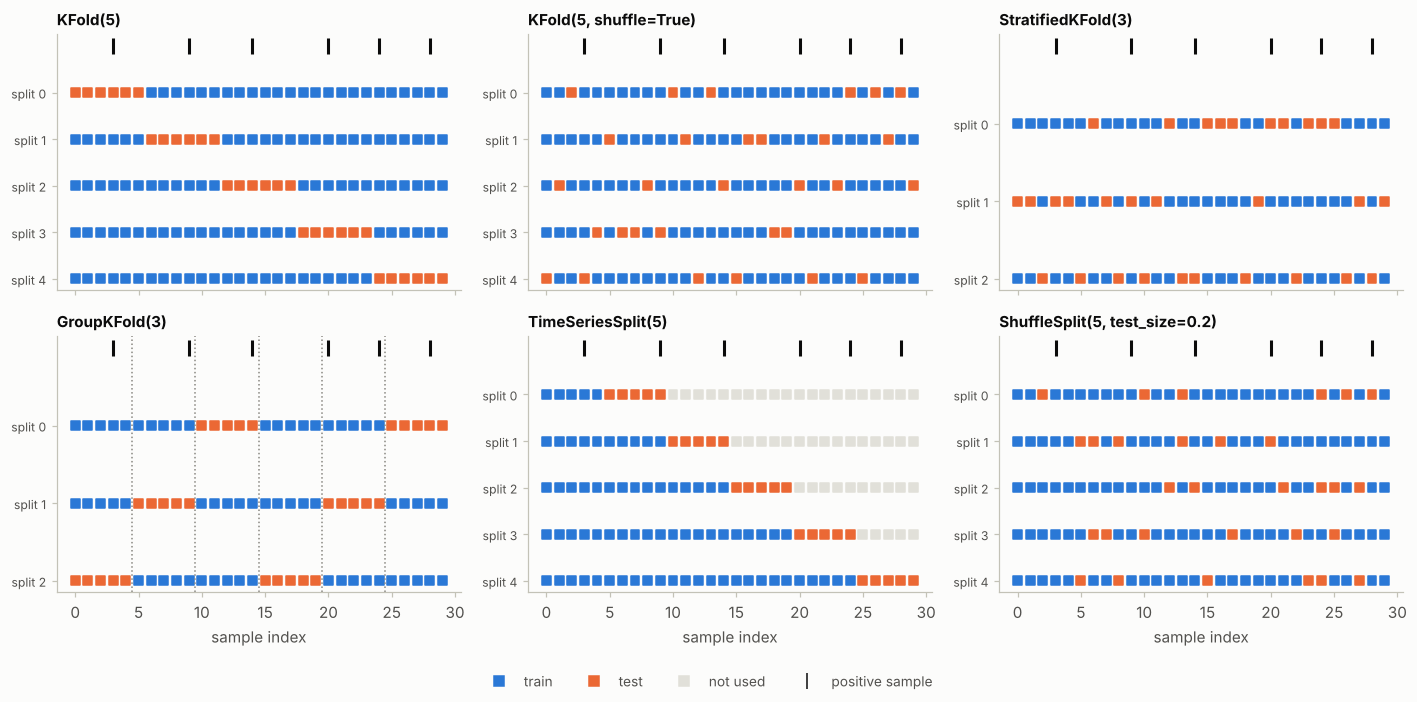

guarantees, checked on the splits above:
  StratifiedKFold(3): positives in each test fold [2, 2, 2] (6 positives in 3 folds)
  GroupKFold(3)     : a group is never on both sides: True
  TimeSeriesSplit(5): the test fold is always after the training part: True; training sizes [5, 10, 15, 20, 25]
  ShuffleSplit(5)   : 8 samples are in the test set of at least two splits, and 9 are never tested


In [13]:
# EXTRA (d): which samples are used for training and for testing in each split
from collections import Counter
from sklearn.model_selection import GroupKFold, ShuffleSplit, TimeSeriesSplit

n = 30
y_demo = np.zeros(n, dtype=int)
y_demo[[3, 9, 14, 20, 24, 28]] = 1
groups_demo = np.repeat(np.arange(6), 5)
X_demo = np.zeros((n, 1))
splitters = [
    ("KFold(5)", KFold(5), None), ("KFold(5, shuffle=True)", KFold(5, shuffle=True, random_state=0), None),
    ("StratifiedKFold(3)", StratifiedKFold(3, shuffle=True, random_state=0), None), ("GroupKFold(3)", GroupKFold(3), groups_demo),
    ("TimeSeriesSplit(5)", TimeSeriesSplit(5), None), ("ShuffleSplit(5, test_size=0.2)", ShuffleSplit(5, test_size=0.2, random_state=0), None),
]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), sharex=True)
for ax, (name, splitter, groups) in zip(axes.ravel(), splitters):
    for i, (train, test) in enumerate(splitter.split(X_demo, y_demo, groups)):
        colours = np.full(n, GRID, dtype=object)
        colours[train], colours[test] = PALETTE[0], PALETTE[1]
        ax.scatter(np.arange(n), np.full(n, i), c=list(colours), marker="s", s=34)
    ax.scatter(np.where(y_demo == 1)[0], np.full(6, -1.0), marker="|", s=120, color=INK, label="positive sample")
    if name.startswith("GroupKFold"):
        for boundary in range(5, n, 5):
            ax.axvline(boundary - 0.5, color=MUTED, ls=":", lw=1)
    ax.set_title(name, fontsize=10)
    ax.set_yticks(range(splitter.get_n_splits(X_demo, y_demo, groups)))
    ax.set_yticklabels([f"split {i}" for i in range(splitter.get_n_splits(X_demo, y_demo, groups))], fontsize=8)
    ax.invert_yaxis()
    ax.grid(False)
for ax in axes[1]:
    ax.set_xlabel("sample index")
fig.legend(handles=[plt.Line2D([], [], marker="s", ls="", color=PALETTE[0], label="train"), plt.Line2D([], [], marker="s", ls="", color=PALETTE[1], label="test"),
                    plt.Line2D([], [], marker="s", ls="", color=GRID, label="not used"), plt.Line2D([], [], marker="|", ls="", color=INK, markersize=10, label="positive sample")],
           loc="lower center", ncol=4, fontsize=9)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

print("guarantees, checked on the splits above:")
print(f"  StratifiedKFold(3): positives in each test fold {[int(y_demo[t].sum()) for _, t in splitters[2][1].split(X_demo, y_demo)]} (6 positives in 3 folds)")
print(f"  GroupKFold(3)     : a group is never on both sides: {all(not set(groups_demo[tr]) & set(groups_demo[te]) for tr, te in splitters[3][1].split(X_demo, y_demo, groups_demo))}")
print(f"  TimeSeriesSplit(5): the test fold is always after the training part: {all(tr.max() < te.min() for tr, te in splitters[4][1].split(X_demo))}; training sizes {[len(tr) for tr, _ in splitters[4][1].split(X_demo)]}")
shuffle_tests = Counter(i for _, te in splitters[5][1].split(X_demo) for i in te)
print(f"  ShuffleSplit(5)   : {sum(c >= 2 for c in shuffle_tests.values())} samples are in the test set of at least two splits, and {n - len(shuffle_tests)} are never tested")

**(e) Leakage through groups.** 30 subjects with 20 measurements each. The features of a subject are a personal "fingerprint" (a random centre plus a little noise) and the label belongs to the *subject* (a random 0 or 1), so the features carry no information about the label of a **new** subject: the honest accuracy is 0.5. A random forest is cross-validated with `KFold` on shuffled rows, which spreads the 20 measurements of each subject over the training and the test folds, and with `GroupKFold`, which keeps a subject on one side.

In [14]:
# EXTRA (e): random k-fold against GroupKFold when each subject contributes many rows
from sklearn.ensemble import RandomForestClassifier

rng = np.random.default_rng(0)
n_subjects, per_subject = 30, 20
subject = np.repeat(np.arange(n_subjects), per_subject)
fingerprint = rng.normal(size=(n_subjects, 5)) * 3
X_subjects = fingerprint[subject] + rng.normal(size=(n_subjects * per_subject, 5)) * 0.5
y_subjects = rng.integers(0, 2, n_subjects)[subject]                           # one random label per subject

rows = []
for name, splitter, kwargs in [("KFold(5, shuffle=True)", KFold(5, shuffle=True, random_state=0), {}), ("GroupKFold(5)", GroupKFold(5), {"groups": subject})]:
    s = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=0), X_subjects, y_subjects, cv=splitter, **kwargs)
    rows.append({"splitter": name, "mean accuracy": s.mean(), "fold accuracies": np.round(s, 2).tolist()})
print("600 rows = 30 subjects x 20 measurements; the label depends on the subject only (honest accuracy: 0.5)\n")
print(pd.DataFrame(rows).set_index("splitter").round(3).to_string())

600 rows = 30 subjects x 20 measurements; the label depends on the subject only (honest accuracy: 0.5)

                        mean accuracy                 fold accuracies
splitter                                                             
KFold(5, shuffle=True)          0.973  [0.96, 0.98, 0.99, 0.97, 0.98]
GroupKFold(5)                   0.528   [0.4, 0.57, 0.81, 0.29, 0.57]


**(f) Leakage through time.** A random walk-like series of 300 points ($x_t = 0.98\, x_{t-1} + \varepsilon_t$) and a regression of $x_t$ on the **time index** $t$ alone, with a 5-nearest-neighbours regressor. Cross-validated with shuffled `KFold`, each test point has its temporal neighbours in the training set and the model "interpolates"; with `TimeSeriesSplit` the model has to **forecast** the future. The score is $R^2$.

In [15]:
# EXTRA (f): random k-fold against TimeSeriesSplit on an autocorrelated series
from sklearn.neighbors import KNeighborsRegressor

rng = np.random.default_rng(1)
series = np.zeros(300)
for t in range(1, 300):
    series[t] = 0.98 * series[t - 1] + rng.normal()
time_index = np.arange(300, dtype=float).reshape(-1, 1)

rows = []
for name, splitter in [("KFold(5, shuffle=True)", KFold(5, shuffle=True, random_state=0)), ("TimeSeriesSplit(5)", TimeSeriesSplit(5))]:
    s = cross_val_score(KNeighborsRegressor(n_neighbors=5), time_index, series, cv=splitter, scoring="r2")
    rows.append({"splitter": name, "mean R2": s.mean(), "fold R2": np.round(s, 2).tolist()})
print("regression of the series on the time index alone (R2 below 0 means worse than predicting the mean of the test fold)\n")
print(pd.DataFrame(rows).set_index("splitter").round(3).to_string())

regression of the series on the time index alone (R2 below 0 means worse than predicting the mean of the test fold)

                        mean R2                             fold R2
splitter                                                           
KFold(5, shuffle=True)    0.934      [0.93, 0.94, 0.94, 0.91, 0.95]
TimeSeriesSplit(5)       -0.113  [-0.0, -0.05, -0.16, -0.24, -0.11]


**Analysis of the extras.**

* **(a)** The PRESS formula gives **3327.655 with one fit**, the same value as the 442 fits of the book. `RidgeCV`, which uses the same shortcut, gives the leave-one-out error of every `alpha` of the grid: 3000.4 for 0.01, 3004.6 for 0.1, 3327.7 for 1, 4851.1 for 10 and 5794.7 for 100. The book's LOOCV was run with `alpha=1.0`, which is **not** the best value: `alpha=0.01` has an error 10% lower.
* **(b)** On the diabetes data the grid search alone reports an $R^2$ of 0.481 (for `alpha` = 0.01) and the nested cross-validation 0.480: the selection bias is **negligible** here (5 candidates, 442 rows), and nested cross-validation costs 130 fits instead of 26 for nothing. The nested mean squared error is 3004.9, close to the leave-one-out value for `alpha` = 0.01, and the mean predictor has 5982.4 (an $R^2$ of $-0.028$ in cross-validation).
* **(c)** With labels that carry no information (true accuracy 0.5), the `best_score_` of a grid of 25 candidates is **0.608** on average (up to 0.700), a "result" 11 points above chance. The nested score is 0.525, close to chance (it is noisy, with a standard deviation of 0.098 per data set of 60 points), and the tuned model scores 0.498 on 5,000 fresh points. Reporting `best_score_` would have claimed a skill that does not exist.
* **(d)** The panels show the guarantees: `KFold` cuts blocks of consecutive rows; the shuffled one spreads them; `StratifiedKFold` puts exactly 2 of the 6 positives in each test fold; every group of `GroupKFold` is the test set of exactly one split; `TimeSeriesSplit` trains on the past only, with training sizes 5, 10, 15, 20 and 25, and the first five samples are never tested; `ShuffleSplit` tests 8 samples in two or more splits and leaves 9 never tested.
* **(e)** When the label belongs to the subject and each subject has 20 rows, a shuffled `KFold` reports an accuracy of **0.973**: the forest recognizes the subject from its fingerprint. `GroupKFold` gives **0.528**, the honest value (0.5) for a new subject, with large fold-to-fold swings (0.29 to 0.81).
* **(f)** A 5-nearest-neighbours regression on the time index reaches an $R^2$ of **0.934** with a shuffled `KFold`, and **$-0.113$** with `TimeSeriesSplit`: interpolating between neighbouring times is easy, forecasting the future is not.

---
## 3. Implementing cross-validation in scikit-learn

*Book: pp. 319–321.*

### Summary

* **Intro** — scikit-learn "offers streamlined tools to implement different cross-validation workflows": `cross_val_score()`, `cross_validate()` and `GridSearchCV()`.
* **Getting ready** — `make_classification(n_samples=500, n_features=10, weights=[0.7, 0.3], random_state=2024)`: 500 samples again, "we will arbitrarily weight the distribution of classes so that the first class comprises 70% of the total dataset".
* **How to do it** — `cross_val_score(model, X, y, cv=5, scoring='accuracy')` (*Mean accuracy: 0.910*); `cross_validate(..., scoring=['accuracy', 'precision', 'recall', 'f1'])` (*Mean precision: 0.875, Mean recall: 0.820, Mean F1: 0.845*); `GridSearchCV(LogisticRegression(), {"C": [0.01, 0.1, 1, 10]}, cv=5, scoring='accuracy')` (*Best hyperparameter (C): 0.1, Best accuracy: 0.918*). The book adds: "Like before, we could have used a stratification approach to our cross-validation, but since we didn't and our dataset is imbalanced, it would be better to use precision, recall, or F1".
* **How it works** — `cross_val_score()` is a quick way to evaluate a model with a single metric, `cross_validate()` captures several metrics, and `GridSearchCV()` "integrates cross-validation with hyperparameter search", which "helps reduce overfitting and improves generalization".
* **Hands-on exercises** — a 7-step workflow: generate a dataset, baseline model, `cross_val_score()`, `cross_validate()`, a grid with `GridSearchCV()`, interpret the metrics.
* **Not in the book's body:** the introduction of the chapter lists a recipe "Model evaluation metrics overview", but the book has no such section. The theory below fills the gap, because the whole recipe is about *which score* to compute.

### Theory

**The three functions and their arguments.**

| Function | Returns | Remarks |
|---|---|---|
| `cross_val_score(est, X, y, cv=, scoring=)` | an array with one score per fold | one metric |
| `cross_validate(est, X, y, cv=, scoring=)` | a dictionary: `fit_time`, `score_time`, `test_<metric>`, and with `return_train_score=True` the `train_<metric>`; optionally `estimator` and `indices` | several metrics; `scoring` may be a list or a dictionary |
| `cross_val_predict(est, X, y, cv=, method=)` | one **out-of-fold prediction** per sample | each prediction comes from a model that did not see the sample; for plots and stacking, **not** for estimating the error (see below) |
| `GridSearchCV`, `RandomizedSearchCV` | a fitted search with `cv_results_`, `best_params_`, `best_score_` and, with `refit=True`, `best_estimator_` refitted on all the data | `best_score_` is the *mean CV score of the best candidate* |

**What `cv=5` means.** An integer is turned into a splitter by `check_cv`: **`StratifiedKFold(5)` when the estimator is a classifier and `y` is binary or multiclass, `KFold(5)` otherwise**, in both cases *without shuffling*. The default `cv=None` is 5-fold. A splitter object, or any iterable of (train, test) index pairs, can be passed instead. The book's remark that "we didn't" use stratification in this recipe is therefore not right; the extras show the folds.

**Scorers: greater is better.** A `scoring` string names a scorer; scorers follow the convention *greater is better*, so error metrics are **negated**: `neg_mean_squared_error`, `neg_log_loss`, `neg_brier_score`. The strings `precision`, `recall` and `f1` mean the **positive class** (label 1); for several classes use `precision_macro`, `f1_weighted` and so on. A scorer can be built from any metric with `make_scorer`.

**A metrics overview.** For a binary classifier with the positive class 1, $TP$, $FP$, $FN$ and $TN$ the entries of the confusion matrix, and $\hat p_i$ the predicted probability of class 1:

| Metric | Definition | Reads |
|---|---|---|
| accuracy | $\dfrac{TP + TN}{n}$ | misleading when a class dominates |
| balanced accuracy | $\tfrac12\left(\dfrac{TP}{TP + FN} + \dfrac{TN}{TN + FP}\right)$ | accuracy that ignores the class sizes; 0.5 for a constant prediction |
| precision, recall, $F_1$ | $\dfrac{TP}{TP + FP}$, $\dfrac{TP}{TP + FN}$, $\dfrac{2\,\text{precision}\cdot\text{recall}}{\text{precision} + \text{recall}}$ | quality of the positive predictions (Chapter 11 discusses them) |
| ROC AUC | probability that a random positive gets a higher score than a random negative | ranking quality, independent of the threshold; 0.5 for chance |
| average precision | $\sum_n (R_n - R_{n-1}) P_n$ over the precision-recall curve | ranking quality for a rare positive class; equals the prevalence for chance |
| log loss | $-\dfrac{1}{n}\sum_i \big[\, y_i \ln \hat p_i + (1 - y_i)\ln(1 - \hat p_i) \,\big]$ | quality of the probabilities; punishes confident mistakes |
| Brier score | $\dfrac{1}{n}\sum_i (\hat p_i - y_i)^2$ | quality of the probabilities; bounded |

For regression: $\mathrm{MSE} = \frac{1}{n}\sum_i (y_i - \hat{y}_i)^2$, $\mathrm{RMSE} = \sqrt{\mathrm{MSE}}$ (same unit as $y$), $\mathrm{MAE} = \frac{1}{n}\sum_i |y_i - \hat{y}_i|$ (less sensitive to large errors) and $R^2$ (section 2), which is negative when the model is worse than predicting the mean. The metric must reflect the **cost of the errors** of the application, and a cross-validated score has to be compared with a **baseline**: `DummyClassifier(strategy='most_frequent')` or `DummyRegressor()`.

**Preprocessing belongs inside the cross-validation.** Any step that *learns from the data* (scaling, imputation, feature selection, dimensionality reduction, resampling) must be fitted on the training part of each fold only. Fitting it on the whole data first lets information from the test fold into the model: **data leakage** (Kaufman et al., 2012). A `Pipeline` passed to `cross_val_score` does it correctly, because it refits every step in every fold.

**Why `cross_val_predict` does not estimate the error.** Each prediction comes from a different model, and the scores are computed on all the predictions together instead of fold by fold. The result is close to the fold-wise mean for a metric such as accuracy, but it can differ for metrics that are not an average over samples (ROC AUC, $F_1$): the scores of different models need not be on a common scale. Use it to inspect the predictions, not to report a score.

### Book code

The data (p. 319) and the three methods (pp. 319–320). The values printed in the book are *0.910*; *0.875*, *0.820*, *0.845*; and *C = 0.1*, *0.918*.

In [16]:
# BOOK CODE (p. 319): load the libraries and the (imbalanced) dataset
# Load the libraries
import numpy as np
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, cross_validate, GridSearchCV

# Load and prepare the dataset
X, y = make_classification(n_samples=500, n_features=10, weights=[0.7, 0.3], random_state=2024)

In [17]:
# BOOK CODE (pp. 319-320): cross_val_score(), cross_validate() and GridSearchCV()
# Use cross_val_score() to compute average accuracy
model = LogisticRegression()
scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')
print(f"Mean accuracy: {np.mean(scores):.3f}")

# Use cross_validate() to compute multiple metrics
results = cross_validate(model, X, y, cv=5,
                         scoring=['accuracy', 'precision', 'recall', 'f1'])
print(f"Mean precision: {np.mean(results['test_precision']):.3f}")
print(f"Mean recall: {np.mean(results['test_recall']):.3f}")
print(f"Mean F1: {np.mean(results['test_f1']):.3f}")

# Use GridSearchCV() for hyperparameter tuning with cross-validation
param_grid = {"C": [0.01, 0.1, 1, 10]}
grid = GridSearchCV(LogisticRegression(), param_grid, cv=5, scoring='accuracy')
grid.fit(X, y)
print(f"Best hyperparameter (C): {grid.best_params_['C']}")
print(f"Best accuracy: {grid.best_score_:.3f}")

Mean accuracy: 0.910
Mean precision: 0.875
Mean recall: 0.820
Mean F1: 0.845
Best hyperparameter (C): 0.1
Best accuracy: 0.918


**Output analysis.**

* The listing prints *Mean accuracy: 0.910*, *Mean precision: 0.875*, *Mean recall: 0.820*, *Mean F1: 0.845*, *Best hyperparameter (C): 0.1* and *Best accuracy: 0.918*, as in the book.
* An accuracy of 0.910 sounds high, but 70% of the samples are in the majority class: a predictor that always answers "0" scores 0.700 (extra (b)). Precision, recall and $F_1$ say more, as the book notes. The mean of the five fold $F_1$ values (0.845) is not the $F_1$ of the mean precision and recall (0.847): the mean of a ratio is not the ratio of the means.
* The best grid value, `C=0.1`, scores 0.918 against 0.910 for the default `C=1`: the difference of 0.008 is of the order of the binomial standard error of an accuracy of 0.91 measured on 500 samples (about 0.013), and `best_score_` is an optimistic number (recipe 4).

### Extra experiments

**(a) What does `cv=5` do?** `check_cv` is the function that `cross_val_score` calls to turn the integer into a splitter. The cell prints the splitter it builds for this classifier and, for comparison, what an unshuffled `KFold(5)` would give: the size of each test fold and the number of positive samples in it.

In [18]:
# EXTRA (a): the splitter behind cv=5, and the class balance of its folds
from sklearn.model_selection import KFold, check_cv

built = check_cv(5, y, classifier=True)
print(f"cv=5 for a classifier is: {built}")
print(f"cv=5 for a regressor is : {check_cv(5, y, classifier=False)}\n")
rows = []
for name, splitter in [("cv=5 (what the book uses)", built), ("KFold(5), no shuffle", KFold(5))]:
    tests = [test for _, test in splitter.split(X, y)]
    rows.append({"splitter": name, "test fold sizes": [len(t) for t in tests], "positives per test fold": [int(y[t].sum()) for t in tests]})
print(pd.DataFrame(rows).set_index("splitter").to_string())
print(f"\nshare of positives in the data: {y.mean():.2f} ({int(y.sum())} of {len(y)})")

cv=5 for a classifier is: StratifiedKFold(n_splits=5, random_state=None, shuffle=False)
cv=5 for a regressor is : KFold(n_splits=5, random_state=None, shuffle=False)

                                     test fold sizes positives per test fold
splitter                                                                    
cv=5 (what the book uses)  [100, 100, 100, 100, 100]    [30, 30, 30, 30, 30]
KFold(5), no shuffle       [100, 100, 100, 100, 100]    [28, 25, 40, 29, 28]

share of positives in the data: 0.30 (150 of 500)


**(b) A baseline, and a metrics overview.** The same cross-validation (`cv=5`) scores a constant "most frequent class" predictor, a random predictor that respects the class proportions, and the logistic regression of the book, with nine metrics. Log loss and Brier score are shown as errors (lower is better).

In [19]:
# EXTRA (b): baselines and the nine metrics of the overview, with cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, make_scorer, precision_score

scorers = {
    "accuracy": "accuracy", "balanced accuracy": "balanced_accuracy",
    "precision": make_scorer(precision_score, zero_division=0), "recall": "recall", "F1": make_scorer(f1_score, zero_division=0),
    "ROC AUC": "roc_auc", "average precision": "average_precision", "log loss": "neg_log_loss", "Brier score": "neg_brier_score",
}
candidates = {
    "constant: most frequent class": DummyClassifier(strategy="most_frequent"),
    "random, class proportions": DummyClassifier(strategy="stratified", random_state=0),
    "LogisticRegression (the book)": LogisticRegression(),
}
table = {}
for name, estimator in candidates.items():
    res = cross_validate(estimator, X, y, cv=5, scoring=scorers)
    column = {metric: res[f"test_{metric}"].mean() for metric in scorers}
    column["log loss"], column["Brier score"] = -column["log loss"], -column["Brier score"]
    table[name] = column
print(pd.DataFrame(table).round(3).to_string())
print(f"\nshare of the majority class (the accuracy of the constant predictor): {1 - y.mean():.2f}; share of the positive class (the average precision of chance): {y.mean():.2f}")

                   constant: most frequent class  random, class proportions  LogisticRegression (the book)
accuracy                                   0.700                      0.598                          0.910
balanced accuracy                          0.500                      0.488                          0.884
precision                                  0.000                      0.278                          0.875
recall                                     0.000                      0.213                          0.820
F1                                         0.000                      0.242                          0.845
ROC AUC                                    0.500                      0.488                          0.963
average precision                          0.300                      0.297                          0.941
log loss                                  10.813                     14.490                          0.214
Brier score                          

**(c) What `cross_validate` returns.** The keys of the dictionary with `return_train_score=True`, and the training and test accuracy of the logistic regression.

In [20]:
# EXTRA (c): the dictionary returned by cross_validate, and the train-test gap
detailed = cross_validate(LogisticRegression(), X, y, cv=5, scoring=["accuracy", "f1"], return_train_score=True, return_estimator=True)
print("keys:", sorted(detailed.keys()))
print(f"accuracy on the training folds: {detailed['train_accuracy'].mean():.3f}; on the test folds: {detailed['test_accuracy'].mean():.3f}; gap {detailed['train_accuracy'].mean() - detailed['test_accuracy'].mean():+.3f}")
print(f"f1 on the training folds      : {detailed['train_f1'].mean():.3f}; on the test folds: {detailed['test_f1'].mean():.3f}")
print(f"number of fitted estimators returned: {len(detailed['estimator'])}; coefficient of the first feature in each: {np.round([e.coef_[0, 0] for e in detailed['estimator']], 3).tolist()}")

keys: ['estimator', 'fit_time', 'score_time', 'test_accuracy', 'test_f1', 'train_accuracy', 'train_f1']
accuracy on the training folds: 0.928; on the test folds: 0.910; gap +0.018
f1 on the training folds      : 0.874; on the test folds: 0.845
number of fitted estimators returned: 5; coefficient of the first feature in each: [0.174, 0.095, 0.327, 0.057, 0.125]


**(d) `cross_val_predict` against the fold-wise mean.** For five metrics, the mean of the five fold scores and the same metric computed once on the pooled out-of-fold predictions (`method='predict_proba'` for the ROC AUC).

In [21]:
# EXTRA (d): pooled out-of-fold predictions against the mean of the fold scores
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score
from sklearn.model_selection import cross_val_predict

pooled_labels = cross_val_predict(LogisticRegression(), X, y, cv=5)
pooled_proba = cross_val_predict(LogisticRegression(), X, y, cv=5, method="predict_proba")[:, 1]
rows = {}
for name, scoring, pooled in [
    ("accuracy", "accuracy", accuracy_score(y, pooled_labels)), ("precision", "precision", precision_score(y, pooled_labels)),
    ("recall", "recall", recall_score(y, pooled_labels)), ("F1", "f1", f1_score(y, pooled_labels)), ("ROC AUC", "roc_auc", roc_auc_score(y, pooled_proba)),
]:
    foldwise = cross_val_score(LogisticRegression(), X, y, cv=5, scoring=scoring).mean()
    rows[name] = {"mean of the 5 fold scores": foldwise, "pooled out-of-fold predictions": pooled, "difference": pooled - foldwise}
print(pd.DataFrame(rows).T.round(4).to_string())

           mean of the 5 fold scores  pooled out-of-fold predictions  difference
accuracy                      0.9100                          0.9100     -0.0000
precision                     0.8750                          0.8723     -0.0027
recall                        0.8200                          0.8200      0.0000
F1                            0.8446                          0.8454      0.0007
ROC AUC                       0.9629                          0.9613     -0.0015


**(e) Leakage through preprocessing.** Two experiments. First, standardizing the features *before* the cross-validation or *inside* a `Pipeline` (200 samples, 20 features). Second, the classic case: 100 samples, 1,000 features of pure noise and random labels, so the true accuracy is 0.5. Selecting the 20 "best" features with `SelectKBest` on all the data and then cross-validating the logistic regression, against the same selection inside a `Pipeline` (20 data sets).

In [22]:
# EXTRA (e): fitting a preprocessing step on all the data before cross-validation
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_s, y_s = make_classification(n_samples=200, n_features=20, random_state=3)
fold_splitter = StratifiedKFold(5, shuffle=True, random_state=0)
scaled_outside = cross_val_score(LogisticRegression(), StandardScaler().fit_transform(X_s), y_s, cv=fold_splitter).mean()
scaled_inside = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression()), X_s, y_s, cv=fold_splitter).mean()
print(f"standardization outside the CV: {scaled_outside:.3f}; inside a Pipeline: {scaled_inside:.3f}\n")

rows = []
for seed in range(20):
    rng = np.random.default_rng(seed)
    X_noise, y_noise = rng.normal(size=(100, 1000)), rng.integers(0, 2, 100)
    splitter = StratifiedKFold(5, shuffle=True, random_state=seed)
    selected = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)                    # looks at all the labels
    leaky = cross_val_score(LogisticRegression(), selected, y_noise, cv=splitter).mean()
    honest = cross_val_score(make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression()), X_noise, y_noise, cv=splitter).mean()
    rows.append({"selection before the CV (leak)": leaky, "selection inside a Pipeline": honest})
print("100 samples, 1,000 pure-noise features, random labels (true accuracy 0.5), 20 data sets:")
print(pd.DataFrame(rows).agg(["mean", "std", "min", "max"]).T.round(3).to_string())

standardization outside the CV: 0.925; inside a Pipeline: 0.930

100 samples, 1,000 pure-noise features, random labels (true accuracy 0.5), 20 data sets:
                                 mean    std   min   max
selection before the CV (leak)  0.817  0.040  0.71  0.89
selection inside a Pipeline     0.519  0.047  0.42  0.59


**Analysis of the extras.**

* **(a)** `cv=5` with a classifier builds **`StratifiedKFold(n_splits=5, shuffle=False)`**: each test fold has 100 samples and exactly **30 positives**. A plain unshuffled `KFold(5)` would put 28, 25, 40, 29 and 28. The book's remark that "we didn't" use stratification is therefore not right: `cross_val_score`, `cross_validate` and `GridSearchCV` stratified the folds by default. For a regressor the same `cv=5` builds a `KFold`.
* **(b)** The constant predictor reaches an accuracy of **0.700**, a balanced accuracy of 0.500, an $F_1$ of 0 and, as chance, an ROC AUC of 0.500 and an average precision of 0.300 (the prevalence of the positive class). The random predictor that respects the class proportions scores 0.598. The logistic regression has an accuracy of 0.910 (21 points above the constant predictor), a balanced accuracy of 0.884, an $F_1$ of 0.845, an ROC AUC of 0.963, an average precision of 0.941, a log loss of 0.214 and a Brier score of 0.062. Accuracy understates how far the model is from the baseline: on $F_1$ the gap is about 84 points. The log loss of the constant predictor (10.8) is huge because it announces probabilities of exactly 0 and 1.
* **(c)** `cross_validate` returns a dictionary with `fit_time`, `score_time`, `test_<metric>`, and with `return_train_score=True` the `train_<metric>`; with `return_estimator=True` it also keeps the five fitted models. The logistic regression scores 0.928 on its training folds and 0.910 on its test folds (gap 0.018; $F_1$ 0.874 and 0.845): a small gap, so little overfitting.
* **(d)** The pooled out-of-fold predictions give the same accuracy (0.9100) and recall (0.8200) as the fold-wise mean, and differences of $-0.0027$ for precision, $+0.0007$ for $F_1$ and $-0.0015$ for the ROC AUC. Here the two ways agree to within 0.003, but nothing guarantees it for a metric that is not an average over samples.
* **(e)** Standardizing before the cross-validation instead of inside the pipeline has no measurable effect on these data (0.925 outside the pipeline against 0.930 inside): scaling is a leak in principle, because the mean and the variance of the test fold enter the transformation, but a mild one. Selecting the 20 best of 1,000 noise features on all the data first gives an accuracy of **0.817** on average (from 0.71 to 0.89) for labels that carry no information; inside a `Pipeline` the same procedure scores **0.519**, the honest chance level. The more a preprocessing step uses the labels, the larger the leak.

---
## 4. Model selection techniques

*Book: pp. 321–324.*

### Summary

* **Intro** — "model selection techniques help us compare different algorithms and configurations in a statistically robust way". The book notes that in the real world business rules, "typically tied to monetary metrics around costs and savings", would also weigh in, and that this recipe uses grid search and randomized search to select "the optimal model based on cross-validation scores".
* **Getting ready** — the dataset of recipe 3 (500 samples, `weights=[0.7, 0.3]`), split with `train_test_split(test_size=0.3, random_state=2024)` into 350 training and 150 test samples.
* **How to do it** — `GridSearchCV(LogisticRegression(), {"C": [0.001, 0.01, 0.1, 1, 10, 100]}, cv=5, scoring='accuracy')` on the training set (*best C: 0.1*); `RandomizedSearchCV` with `loguniform(1e-3, 1e2)`, `n_iter=10`, `random_state=2024` (*best C: 0.1744*); the final model `random_search.best_estimator_` scored on the test set (*Final accuracy on test set: 0.940*).
* **How it works** — `GridSearchCV` "performs an exhaustive search across the specified hyperparameter grid", which "can become computationally expensive as the number of parameters grows"; `RandomizedSearchCV` "samples a fixed number of parameter combinations from distributions we specify. It's often more efficient and yields comparable results with fewer evaluations". The selected configuration is then validated "on unseen test data".
* **Hands-on exercises** — a 7-step workflow: split, grid search, randomized search with a continuous distribution, compare the test performance of both tuned models, "reflect on time and accuracy trade-offs".

### Theory

**Hyperparameter tuning as optimization of a noisy function.** The hyperparameters $\lambda$ (such as `C`) are not learned by the fit. Model selection chooses the $\lambda$ with the best cross-validated score $\widehat{\mathrm{Err}}_{\mathrm{CV}}(\lambda)$. This function is **noisy** (recipe 1 measured its noise), so candidates whose scores differ by less than the noise cannot be told apart.

**Grid search.** It evaluates every combination of the listed values: $|\Lambda_1| \times |\Lambda_2| \times \dots$ candidates, each fitted $k$ times, plus one refit of the winner on all the training data (`refit=True`). The cost grows **exponentially** with the number of hyperparameters.

**Random search.** Bergstra and Bengio (2012) argue and show that random search is more efficient than grid search because *only a few hyperparameters really matter* for a given data set. A grid with $N$ points in $d$ dimensions tries only $N^{1/d}$ distinct values of each hyperparameter, while $N$ random points try $N$ distinct values of every one. If one hyperparameter is irrelevant, most of the grid's evaluations repeat the same effective configuration. Scale parameters such as `C` or `gamma` act multiplicatively, so they are drawn from a **log-uniform** distribution (`scipy.stats.loguniform`) and not from a uniform one. The cost of a random search is `n_iter` $\times\, k$ fits, whatever the number of hyperparameters; it is set by the user, not by the grid.

**Counting the fits.** For a search with $c$ candidates and $k$ folds: $c \times k$ fits plus one refit. The book's grid has $6 \times 5 = 30$, its randomized search $10 \times 5 = 50$.

**Selecting and then reporting.** The best score of a search is optimistic (recipe 2). The honest estimate of the selected model comes from data that took no part in the search: a **test set** kept apart from the start (as in this recipe), or a nested cross-validation. The test set must be used **once**; looking at it to decide again turns it into a validation set.

**The metric picks the winner.** `scoring` defines what "best" means. Accuracy, $F_1$, ROC AUC and log loss rank candidates differently, because they reward different things (the decision at one threshold, the ranking of the scores, the quality of the probabilities). The metric must come from the application, not from the default.

**The one-standard-error rule.** When several candidates are statistically indistinguishable from the best, prefer the **simplest** (for example the strongest regularization) among those whose mean score is within one standard error of the best (Breiman et al., 1984; Hastie, Tibshirani and Friedman, 2009). It removes part of the selection noise.

**Beyond the two searches.** *Successive halving* (`HalvingGridSearchCV`, `HalvingRandomSearchCV`, still behind an experimental import) gives every candidate a small budget and keeps only the best ones for more (Jamieson and Talwalkar, 2016). Bayesian optimization is available in other libraries.

### Book code

The data and the split (p. 322), then the two searches and the test accuracy (pp. 322–323). The values printed in the book are *C = 0.1*, *C = 0.1744* and *0.940*.

In [23]:
# BOOK CODE (p. 322): load the libraries, generate and split the dataset
# Load the libraries
import numpy as np
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split
from sklearn.metrics import accuracy_score

# Load and split the dataset
X, y = make_classification(n_samples=500, n_features=10, weights=[0.7, 0.3], random_state=2024)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [24]:
# BOOK CODE (pp. 322-323): GridSearchCV, RandomizedSearchCV and the final accuracy
# Use GridSearchCV to evaluate all combinations in the parameter grid
param_grid = {"C": [0.001, 0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(LogisticRegression(), param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)
print(f"GridSearchCV best C: {grid.best_params_['C']}")

# Use RandomizedSearchCV to evaluate a random sample of parameters
from scipy.stats import loguniform
param_dist = {"C": loguniform(1e-3, 1e2)}
random_search = RandomizedSearchCV(LogisticRegression(), param_distributions=param_dist,
                                    n_iter=10, cv=5, scoring='accuracy', random_state=2024)
random_search.fit(X_train, y_train)
print(f"RandomizedSearchCV best C: {random_search.best_params_['C']:.4f}")

# Evaluate final model performance
final_model = random_search.best_estimator_
y_pred = final_model.predict(X_test)
print(f"Final accuracy on test set: {accuracy_score(y_test, y_pred):.3f}")

GridSearchCV best C: 0.1
RandomizedSearchCV best C: 0.1744
Final accuracy on test set: 0.940


**Output analysis.**

* The listing prints *GridSearchCV best C: 0.1*, *RandomizedSearchCV best C: 0.1744* and *Final accuracy on test set: 0.940*, as in the book.
* The book evaluates on the test set **only the winner of the randomized search**. The grid's winner is not scored, so the comparison that the recipe suggests (which search is better?) is not made; extra (c) makes it.

### Extra experiments

**(a) How many evaluations does each search make?** The number of candidates, of distinct values of `C` tried, and of fits, read from `cv_results_`.

In [25]:
# EXTRA (a): the cost of the two searches
rows = []
for name, search in [("GridSearchCV", grid), ("RandomizedSearchCV", random_search)]:
    results = pd.DataFrame(search.cv_results_)
    n_splits = len([c for c in results.columns if c.startswith("split") and c.endswith("_test_score")])
    rows.append({
        "search": name, "candidates": len(results), "distinct values of C": results["param_C"].nunique(), "folds": n_splits,
        "fits for the search": len(results) * n_splits, "plus refit": 1, "total fits": len(results) * n_splits + 1,
        "lowest C tried": float(results["param_C"].min()), "highest C tried": float(results["param_C"].max()),
    })
print(pd.DataFrame(rows).set_index("search").to_string())

                    candidates  distinct values of C  folds  fits for the search  plus refit  total fits  lowest C tried  highest C tried
search                                                                                                                                   
GridSearchCV                 6                     6      5                   30           1          31        0.001000       100.000000
RandomizedSearchCV          10                    10      5                   50           1          51        0.001656         4.327138


**(b) Reading `cv_results_`.** The mean score, its standard deviation across the 5 folds and its rank for each candidate. The figure plots the mean score against `C` (log scale) with a band of one standard deviation; the grid candidates are the line, the random candidates are the triangles. The dotted line is the one-standard-error threshold: the best mean score minus its standard error ($\text{sd} / \sqrt{5}$).

grid search:
      C  mean CV accuracy  sd over the 5 folds  rank
  0.001            0.6943               0.0114     6
  0.010            0.8771               0.0265     5
  0.100            0.8943               0.0171     1
  1.000            0.8857               0.0156     4
 10.000            0.8886               0.0167     2
100.000            0.8886               0.0167     2

random search:
     C  mean CV accuracy  sd over the 5 folds  rank
0.0017            0.7143               0.0202    10
0.0034            0.7571               0.0271     9
0.0087            0.8629               0.0265     8
0.0106            0.8771               0.0265     7
0.1744            0.8971               0.0190     1
0.2340            0.8943               0.0146     2
0.8711            0.8857               0.0156     5
2.4946            0.8857               0.0156     5
3.1300            0.8886               0.0167     3
4.3271            0.8886               0.0167     3

best grid candidate: C = 0.

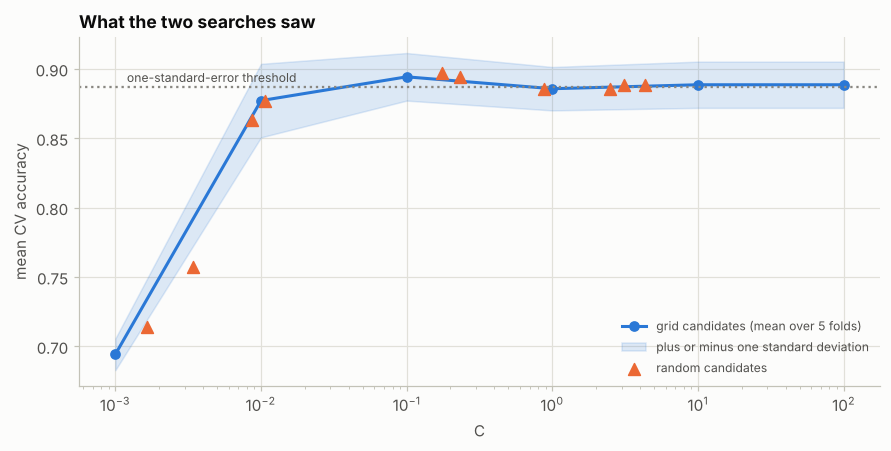

In [26]:
# EXTRA (b): the cross-validation scores of every candidate, and the one-standard-error threshold
grid_results = pd.DataFrame(grid.cv_results_)[["param_C", "mean_test_score", "std_test_score", "rank_test_score"]].astype({"param_C": float})
random_results = pd.DataFrame(random_search.cv_results_)[["param_C", "mean_test_score", "std_test_score", "rank_test_score"]].astype({"param_C": float}).sort_values("param_C")
for title, frame in [("grid", grid_results), ("random", random_results)]:
    print(f"{title} search:\n{frame.rename(columns={'param_C': 'C', 'mean_test_score': 'mean CV accuracy', 'std_test_score': 'sd over the 5 folds', 'rank_test_score': 'rank'}).round(4).to_string(index=False)}\n")

best_row = grid_results.loc[grid_results["mean_test_score"].idxmax()]
threshold = best_row["mean_test_score"] - best_row["std_test_score"] / np.sqrt(5)
within = grid_results[grid_results["mean_test_score"] >= threshold]
print(f"best grid candidate: C = {best_row['param_C']:g}, mean {best_row['mean_test_score']:.4f}; one-standard-error threshold {threshold:.4f}")
print(f"grid candidates at or above the threshold: C = {within['param_C'].tolist()}; the simplest (smallest C, strongest regularization): C = {within['param_C'].min():g}")

fig, ax = plt.subplots(figsize=(8.2, 4.2))
ax.plot(grid_results["param_C"], grid_results["mean_test_score"], color=PALETTE[0], marker="o", label="grid candidates (mean over 5 folds)")
ax.fill_between(grid_results["param_C"], grid_results["mean_test_score"] - grid_results["std_test_score"], grid_results["mean_test_score"] + grid_results["std_test_score"], color=PALETTE[0], alpha=0.15, label="plus or minus one standard deviation")
ax.scatter(random_results["param_C"], random_results["mean_test_score"], color=PALETTE[1], marker="^", s=60, zorder=3, label="random candidates")
ax.axhline(threshold, color=MUTED, ls=":", lw=1.5)
ax.text(1.2e-3, threshold + 0.004, "one-standard-error threshold", color=INK_SOFT, fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("C")
ax.set_ylabel("mean CV accuracy")
ax.set_title("What the two searches saw")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

**(c) The test accuracy of each choice.** The book reports the test accuracy of the randomized search only. The cell computes that of both searches, and of several values of `C`, together with the number of correct test predictions and the standard error of an accuracy measured on 150 points.

In [27]:
# EXTRA (c): test accuracy of the two selected models and of other values of C
rows = []
for label, estimator in [("grid winner", grid.best_estimator_), ("random winner", random_search.best_estimator_)]:
    pred = estimator.predict(X_test)
    rows.append({"model": f"{label} (C = {estimator.C:.4g})", "correct test predictions": int((pred == y_test).sum()), "test accuracy": accuracy_score(y_test, pred)})
for C in [0.001, 0.01, 1, 10, 100]:
    pred = LogisticRegression(C=C).fit(X_train, y_train).predict(X_test)
    rows.append({"model": f"C = {C:g}", "correct test predictions": int((pred == y_test).sum()), "test accuracy": accuracy_score(y_test, pred)})
print(pd.DataFrame(rows).set_index("model").round(4).to_string())
differ = int((grid.best_estimator_.predict(X_test) != random_search.best_estimator_.predict(X_test)).sum())
acc = accuracy_score(y_test, random_search.best_estimator_.predict(X_test))
print(f"\nthe two winners predict differently on {differ} of {len(y_test)} test samples")
print(f"binomial standard error of an accuracy of {acc:.3f} measured on {len(y_test)} points: {np.sqrt(acc * (1 - acc) / len(y_test)):.3f}")

                            correct test predictions  test accuracy
model                                                              
grid winner (C = 0.1)                            140         0.9333
random winner (C = 0.1744)                       141         0.9400
C = 0.001                                        108         0.7200
C = 0.01                                         140         0.9333
C = 1                                            141         0.9400
C = 10                                           141         0.9400
C = 100                                          141         0.9400

the two winners predict differently on 1 of 150 test samples
binomial standard error of an accuracy of 0.940 measured on 150 points: 0.019


**(d) The metric picks the winner.** The same grid is run with six scoring functions. The table gives the best `C` and the best mean score for each.

In [28]:
# EXTRA (d): the best C depends on the metric
rows = []
for scoring in ["accuracy", "balanced_accuracy", "f1", "roc_auc", "average_precision", "neg_log_loss"]:
    search = GridSearchCV(LogisticRegression(), param_grid, cv=5, scoring=scoring).fit(X_train, y_train)
    rows.append({"scoring": scoring, "best C": search.best_params_["C"], "best mean CV score": search.best_score_})
print(pd.DataFrame(rows).set_index("scoring").round(4).to_string())

                   best C  best mean CV score
scoring                                      
accuracy            0.100              0.8943
balanced_accuracy  10.000              0.8635
f1                  0.100              0.8150
roc_auc             0.001              0.9662
average_precision   0.001              0.9382
neg_log_loss        1.000             -0.2304


**(e) Random search against grid search under a budget.** 15 different data sets of 400 samples (4 informative features out of 10), each split 60/40. An `SVC` has two hyperparameters, `C` and `gamma`. The grid has $6 \times 6 = 36$ candidates (180 fits); the random search draws only 12 candidates (60 fits) from log-uniform distributions over the same ranges. The table averages the best cross-validation score and the accuracy on the 40% test part.

In [29]:
# EXTRA (e): a third of the budget for random search, on a problem with two hyperparameters
from sklearn.svm import SVC

rows = []
for seed in range(15):
    X_s, y_s = make_classification(n_samples=400, n_features=10, n_informative=4, random_state=seed)
    X_a, X_b, y_a, y_b = train_test_split(X_s, y_s, test_size=0.4, random_state=seed)
    exhaustive = GridSearchCV(SVC(random_state=0), {"C": np.logspace(-2, 3, 6), "gamma": np.logspace(-4, 1, 6)}, cv=5).fit(X_a, y_a)
    sampled = RandomizedSearchCV(SVC(random_state=0), {"C": loguniform(1e-2, 1e3), "gamma": loguniform(1e-4, 1e1)}, n_iter=12, cv=5, random_state=seed).fit(X_a, y_a)
    rows.append({"grid: best CV": exhaustive.best_score_, "random: best CV": sampled.best_score_, "grid: test": exhaustive.score(X_b, y_b), "random: test": sampled.score(X_b, y_b)})
outcome = pd.DataFrame(rows)
print(f"grid search: 36 candidates, 180 fits; random search: 12 candidates, 60 fits; 15 data sets\n")
print(pd.DataFrame({"mean": outcome.mean(), "sd": outcome.std()}).round(4).to_string())
gap = outcome['random: test'] - outcome['grid: test']
print(f"\nrandom search at least as good as the grid on the test part in {(gap >= -1e-12).mean():.0%} of the data sets (wins {(gap > 1e-12).sum()}, ties {(gap.abs() <= 1e-12).sum()}, losses {(gap < -1e-12).sum()}); mean test difference (random - grid) {gap.mean():+.4f}, standard error {gap.std() / np.sqrt(len(gap)):.4f}")

grid search: 36 candidates, 180 fits; random search: 12 candidates, 60 fits; 15 data sets

                   mean      sd
grid: best CV    0.8903  0.0491
random: best CV  0.8867  0.0513
grid: test       0.8887  0.0492
random: test     0.8825  0.0530

random search at least as good as the grid on the test part in 60% of the data sets (wins 7, ties 2, losses 6); mean test difference (random - grid) -0.0062, standard error 0.0057


**(f) The winner's curse.** 20 data sets with only 100 training samples and 3,000 fresh samples. The 36-candidate grid of the previous experiment is searched on the training part; the cell compares `best_score_` with the accuracy of the winner on the fresh samples.

In [30]:
# EXTRA (f): best_score_ against the accuracy on fresh data, small training sets
rows = []
for seed in range(20):
    X_all, y_all = make_classification(n_samples=3100, n_features=10, n_informative=4, random_state=seed)
    search = GridSearchCV(SVC(random_state=0), {"C": np.logspace(-2, 3, 6), "gamma": np.logspace(-4, 1, 6)}, cv=5).fit(X_all[:100], y_all[:100])
    rows.append({"best_score_ (CV on 100 samples)": search.best_score_, "accuracy on 3,000 fresh samples": search.score(X_all[100:], y_all[100:])})
curse = pd.DataFrame(rows)
curse["optimism"] = curse.iloc[:, 0] - curse.iloc[:, 1]
print(pd.DataFrame({"mean": curse.mean(), "sd": curse.std(), "positive in": (curse > 0).mean()}).round(4).to_string())

                                   mean      sd  positive in
best_score_ (CV on 100 samples)  0.8965  0.0362         1.00
accuracy on 3,000 fresh samples  0.8649  0.0455         1.00
optimism                         0.0316  0.0476         0.65


**Analysis of the extras.**

* **(a)** The grid has 6 candidates and makes $6 \times 5 = 30$ fits (plus the refit); the randomized search has 10 candidates and makes $10 \times 5 =$ **50 fits**. In the book's own example the random search is therefore *more* expensive than the grid; "fewer evaluations" holds only when the grid has more points than `n_iter` (extra (e)). The random draws are all different (10 distinct values of `C`, from 0.0017 to 4.33), whereas the grid has 6.
* **(b)** The cross-validation accuracy of the grid is 0.694 for `C=0.001`, 0.877 for 0.01, **0.894 for 0.1**, 0.886 for 1 and 0.889 for both 10 and 100 (the two have the same score and the same rank: for large enough `C` the regularization no longer changes the predictions). The standard deviation over the five folds is 0.011 to 0.027, larger than the difference between `C=0.1` and `C=100` (0.006): above `C=0.01` the candidates cannot be told apart. The random candidates fall on the same curve (the best, 0.897, is at `C=0.1744`). The one-standard-error threshold is 0.8866; the grid candidates at or above it are `C` = 0.1, 10 and 100 (`C=1` is just below), and the simplest of them is the best itself, so the rule changes nothing here.
* **(c)** The grid's winner (`C=0.1`) classifies **140 of the 150** test samples correctly (0.933), the random winner (`C=0.1744`) **141** (0.940): the two models predict differently on a single sample. Every `C` from 0.1744 to 100 gets 141, `C=0.01` gets 140 and `C=0.001` only 108 (0.720). The binomial standard error of an accuracy of 0.940 on 150 points is 0.019, so the "better" search of the book is one test sample ahead of the other, and no more.
* **(d)** The best `C` depends on the metric: 0.1 for accuracy (0.894) and $F_1$ (0.815), 10 for balanced accuracy (0.864), 1 for log loss ($-0.230$), and **0.001** for the ROC AUC (0.966) and the average precision (0.938). The last two depend only on the *ordering* of the scores, and the strongly regularized model ranks the samples as well as any other even though its accuracy is only 0.694: accuracy needs the scores to sit on the right side of the 0.5 threshold, ranking does not. The metric must come from the application before the search is run.
* **(e)** Over 15 data sets with two hyperparameters, the 36-candidate grid (180 fits) reaches a best CV score of 0.8903 and a test accuracy of 0.8887; the random search with 12 candidates (60 fits, a third of the budget) reaches 0.8867 and 0.8825, 0.6 points below the grid on the test part. That difference is **not detectable**: its standard error over the 15 data sets is 0.6 points, and the random search wins, ties and loses in 7, 2 and 6 data sets (it is at least as good in 60% of them).
* **(f)** With only 100 training samples, the `best_score_` of the 36-candidate grid is **0.8965** on average, and the winner scores 0.8649 on 3,000 fresh samples: an optimism of **+0.032** (positive for 65% of the data sets). This is the winner's curse, and it is why `best_score_` must not be reported as the performance of the final model.

---
## 5. Evaluating model generalizability

*Book: pp. 324–328.*

### Summary

* **Intro** — a good score on training and validation sets does not guarantee generalization, and "even when it does, when initially put into production, data changes over time, so today's well-performing model is tomorrow's failed predictor". This "inevitable degradation" is what machine learning operations (MLOps) exists to monitor, retraining the model when performance falls below an acceptable level.
* **Getting ready** — `make_classification(n_samples=1000, n_features=20, weights=[0.7, 0.3], random_state=2024)`.
* **How to do it** — `learning_curve(LogisticRegression(), X, y, cv=5, scoring='accuracy', train_sizes=np.linspace(0.1, 1.0, 5), random_state=2024)` and a plot (Figure 12.1); `validation_curve` over `C = np.logspace(-3, 2, 6)` and a plot (Figure 12.2). Reading of the learning curve: the training score "is almost always going to be high" and "stays relatively flat"; the cross-validation score "improves rapidly" and "both lines begin to converge around 800 samples"; with more data "we'd probably see both lines level off" because of "the law of diminishing returns". The validation curve shows that "further adjustment elicits no great improvement".
* **How it works** — "a gap between the two lines often signals overfitting, while convergence suggests good generalization"; for the validation curve "small values of C lead to strong regularization, potentially underfitting the data, while large values of C reduce regularization and may cause overfitting".
* **Hands-on exercises** — a 7-step workflow: learning curve, validation curve, plot both, decide whether the model overfits, underfits or generalizes, and use the insight "to guide further data collection or hyperparameter tuning".

### Theory

**The decomposition of the error.** For squared loss and a target $y = f(x) + \varepsilon$ with noise variance $\sigma^2$, the expected error of a model fitted on a random training set, at a point $x$, is
$$\mathbb{E}\big[(y - \hat{f}(x))^2\big] = \underbrace{\sigma^2}_{\text{noise}} + \underbrace{\big(\mathbb{E}[\hat{f}(x)] - f(x)\big)^2}_{\text{bias}^2} + \underbrace{\operatorname{Var}\big(\hat{f}(x)\big)}_{\text{variance}}$$
(Geman, Bienenstock and Doursat, 1992). A model that is too simple has a large **bias** (it *underfits*: it cannot represent the truth, however much data it sees). A model that is too flexible has a large **variance** (it *overfits*: it follows the noise of the particular training set). For classification there is no unique decomposition but the same picture holds.

**Learning curve.** The score of a model trained on the first $m$ samples of each training fold, against $m$: the *training score* is measured on those $m$ samples, the *validation score* on the held-out fold. How to read it:

* *High bias*: both curves are **low and close together**, flat as $m$ grows. More data does not help; a more flexible model or better features do.
* *High variance*: a **large gap** between a high training score and a lower validation score, closing slowly. More data, stronger regularization or a simpler model help.
* *Good fit*: both curves converge to a high value. The remaining question is whether the plateau has been reached, which tells whether more data would still pay off.

**Validation curve.** The same two scores against **one hyperparameter** at a fixed data size, such as `C`, the inverse of the regularization strength: small `C` means strong regularization (high bias), large `C` weak regularization (high variance). For a model whose capacity does not matter much, the curve is simply flat. Both curves are cross-validated, so they carry the noise of recipe 1; the validation score is also a selection (the best point of the curve is optimistic).

**What cross-validation cannot see.** Cross-validation estimates the performance on new data **drawn from the same distribution as the sample**. If the distribution changes after deployment (*covariate shift*: the inputs change; *label shift*: the class proportions change; *concept drift*: the relation between inputs and target changes), the estimate no longer applies. This is the problem that the book's introduction assigns to MLOps and that Chapter 13 takes up: monitoring and retraining.

### Book code

The data (p. 324–325), then the learning curve with its figure (Figure 12.1, p. 326) and the validation curve with its figure (Figure 12.2, p. 327).

In [31]:
# BOOK CODE (pp. 324-325): load the libraries and the dataset
# Load the libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import learning_curve, validation_curve

# Load the dataset
X, y = make_classification(n_samples=1000, n_features=20, weights=[0.7, 0.3], random_state=2024)

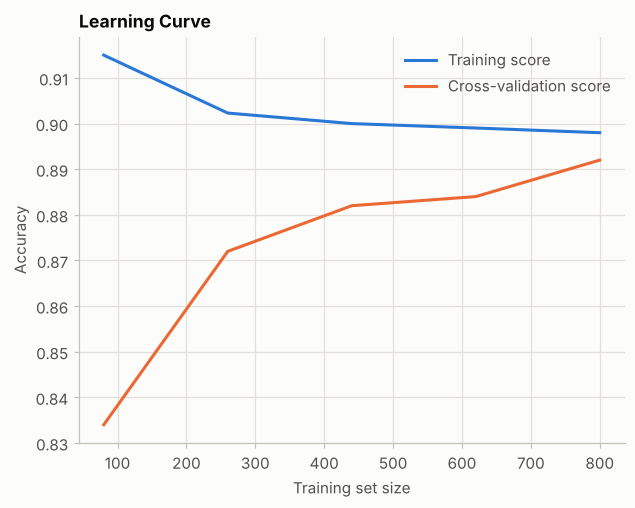

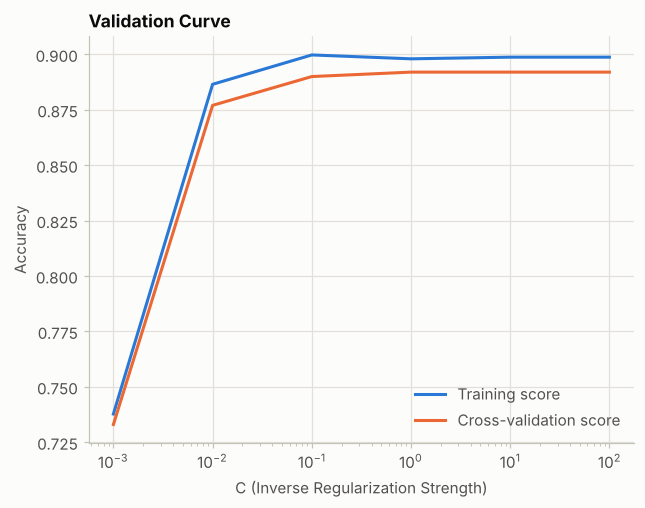

In [32]:
# BOOK CODE (pp. 325-327): the learning curve and the validation curve
# Plot a learning curve
train_sizes, train_scores, test_scores = learning_curve(
    LogisticRegression(), X, y, cv=5, scoring='accuracy', train_sizes=np.linspace(0.1, 1.0, 5), random_state=2024)

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.plot(train_sizes, train_mean, label='Training score')
plt.plot(train_sizes, test_mean, label='Cross-validation score')
plt.xlabel('Training set size')
plt.ylabel('Accuracy')
plt.title('Learning Curve')
plt.legend()
plt.grid(True)
plt.show()

# Plot a validation curve
param_range = np.logspace(-3, 2, 6)
train_scores, test_scores = validation_curve(
    LogisticRegression(), X, y, param_name="C", param_range=param_range,
    cv=5, scoring='accuracy')

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.semilogx(param_range, train_mean, label='Training score')
plt.semilogx(param_range, test_mean, label='Cross-validation score')
plt.xlabel('C (Inverse Regularization Strength)')
plt.ylabel('Accuracy')
plt.title('Validation Curve')
plt.legend()
plt.grid(True)
plt.show()

**Output analysis.**

* Figure 12.1: the training score goes from 0.915 (80 samples) to 0.898 (800), nearly flat, and the cross-validation score from 0.834 to 0.892. The sizes are 80, 260, 440, 620 and 800 because each of the 5 training folds has $1000 \times 4/5 = 800$ samples: **800 is the largest size that can be plotted**, so "the lines converge around 800 samples" describes the end of the figure; the gap is already 0.015 at 620 and 0.006 at 800.
* Figure 12.2: the validation score is 0.733 for `C=0.001` (barely above the 0.695 of a constant predictor: underfitting), then 0.877, 0.890 and **0.892 from `C=1` onwards**; the training score is 0.738, 0.887, 0.900 and 0.898 to 0.899. The two curves stay together: there is **no overfitting at large `C`** in this example, only a plateau, as the book says of the learning curve ("diminishing returns").

### Extra experiments

**(a) The numbers behind the two figures.** The mean and standard deviation over the 5 folds of the training and validation scores, for each size and each value of `C`.

In [33]:
# EXTRA (a): the values plotted in Figures 12.1 and 12.2, with their spread over the folds
sizes, tr_sc, va_sc = learning_curve(LogisticRegression(), X, y, cv=5, scoring="accuracy", train_sizes=np.linspace(0.1, 1.0, 5))
curve = pd.DataFrame({
    "training size": sizes, "training score": tr_sc.mean(1), "sd": tr_sc.std(1), "validation score": va_sc.mean(1), "sd ": va_sc.std(1), "gap": tr_sc.mean(1) - va_sc.mean(1),
})
print("learning curve (5 folds of 1,000 samples: at most 800 training samples):")
print(curve.round(3).to_string(index=False))

tr_v, va_v = validation_curve(LogisticRegression(), X, y, param_name="C", param_range=param_range, cv=5, scoring="accuracy")
validation = pd.DataFrame({"C": param_range, "training score": tr_v.mean(1), "sd": tr_v.std(1), "validation score": va_v.mean(1), "sd ": va_v.std(1), "gap": tr_v.mean(1) - va_v.mean(1)})
print("\nvalidation curve:")
print(validation.round(3).to_string(index=False))
print(f"\naccuracy of a constant 'majority class' prediction on these data: {1 - y.mean():.3f}")

learning curve (5 folds of 1,000 samples: at most 800 training samples):
 training size  training score    sd  validation score   sd    gap
            80           0.915 0.020             0.834 0.034 0.081
           260           0.902 0.008             0.872 0.041 0.030
           440           0.900 0.008             0.882 0.025 0.018
           620           0.899 0.010             0.884 0.024 0.015
           800           0.898 0.007             0.892 0.024 0.006

validation curve:
      C  training score    sd  validation score   sd    gap
  0.001           0.738 0.008             0.733 0.015 0.005
  0.010           0.887 0.007             0.877 0.023 0.010
  0.100           0.900 0.006             0.890 0.021 0.010
  1.000           0.898 0.007             0.892 0.024 0.006
 10.000           0.899 0.006             0.892 0.024 0.007
100.000           0.899 0.006             0.892 0.024 0.007

accuracy of a constant 'majority class' prediction on these data: 0.695


**(b) Is `random_state` used by `learning_curve`?** The learning curve is computed with `random_state` 2024 and 7, and with `shuffle=True` for both seeds.

In [34]:
# EXTRA (b): random_state only matters when shuffle=True
def lc_validation_scores(**kwargs):
    return learning_curve(LogisticRegression(), X, y, cv=5, scoring="accuracy", train_sizes=np.linspace(0.1, 1.0, 5), **kwargs)[2]


no_shuffle_a, no_shuffle_b = lc_validation_scores(random_state=2024), lc_validation_scores(random_state=7)
shuffle_a, shuffle_b = lc_validation_scores(shuffle=True, random_state=2024), lc_validation_scores(shuffle=True, random_state=7)
print(f"shuffle=False (the default and the book's call): largest difference between random_state 2024 and 7: {np.abs(no_shuffle_a - no_shuffle_b).max():.4f}")
print(f"shuffle=True                                   : largest difference between random_state 2024 and 7: {np.abs(shuffle_a - shuffle_b).max():.4f}")

shuffle=False (the default and the book's call): largest difference between random_state 2024 and 7: 0.0000
shuffle=True                                   : largest difference between random_state 2024 and 7: 0.0800


**(c) Does the learning curve level off?** The book predicts that, with more data, both lines "level off". A data set with 6,000 samples generated with the same recipe allows a learning curve up to 4,800 training samples; the dashed line marks the 800 samples of the book's figure.

 training size  training score  validation score     gap
            80          0.9675            0.8697  0.0978
           260          0.9354            0.9320  0.0034
           440          0.9445            0.9368  0.0077
           620          0.9448            0.9413  0.0035
           800          0.9468            0.9413  0.0054
          1600          0.9436            0.9452 -0.0015
          2400          0.9455            0.9452  0.0003
          3200          0.9444            0.9457 -0.0013
          4800          0.9469            0.9462  0.0008


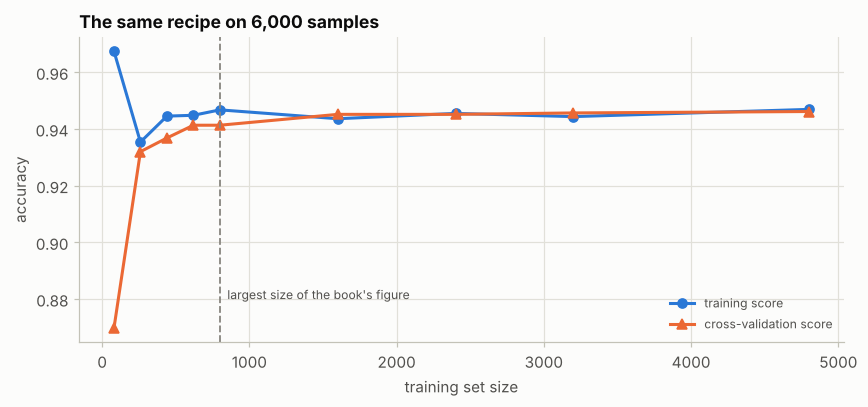

In [35]:
# EXTRA (c): the same recipe on 6,000 samples, with training sets up to 4,800
X_big, y_big = make_classification(n_samples=6000, n_features=20, weights=[0.7, 0.3], random_state=2024)
sizes_big, tr_big, va_big = learning_curve(LogisticRegression(), X_big, y_big, cv=5, scoring="accuracy", train_sizes=[80, 260, 440, 620, 800, 1600, 2400, 3200, 4800])
print(pd.DataFrame({"training size": sizes_big, "training score": tr_big.mean(1), "validation score": va_big.mean(1), "gap": tr_big.mean(1) - va_big.mean(1)}).round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(sizes_big, tr_big.mean(1), color=PALETTE[0], marker="o", label="training score")
ax.plot(sizes_big, va_big.mean(1), color=PALETTE[1], marker="^", label="cross-validation score")
ax.axvline(800, color=MUTED, ls="--", lw=1.2)
ax.text(850, 0.88, "largest size of the book's figure", color=INK_SOFT, fontsize=8)
ax.set_xlabel("training set size")
ax.set_ylabel("accuracy")
ax.set_title("The same recipe on 6,000 samples")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

**(d) High bias against high variance.** A problem that a straight line cannot solve: `make_moons` with 2,000 samples and noise 0.35. Three models: a logistic regression (too simple), an unpruned decision tree (too flexible) and a decision tree limited to depth 4. The figure shows their learning curves; the table gives the gap at the largest size.

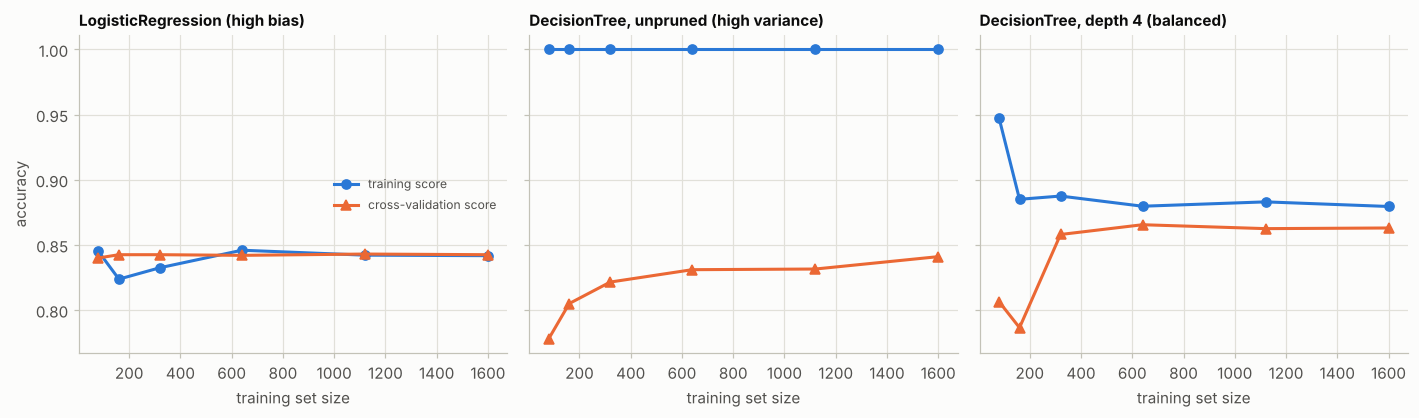

                                        training score at 1,600  validation score at 1,600    gap  validation score at 80
model                                                                                                                    
LogisticRegression (high bias)                            0.842                      0.842 -0.001                   0.840
DecisionTree, unpruned (high variance)                    1.000                      0.841  0.159                   0.778
DecisionTree, depth 4 (balanced)                          0.880                      0.863  0.017                   0.806


In [36]:
# EXTRA (d): learning curves of a model with high bias and of a model with high variance
from sklearn.datasets import make_moons
from sklearn.tree import DecisionTreeClassifier

X_moons, y_moons = make_moons(n_samples=2000, noise=0.35, random_state=0)
models = [("LogisticRegression (high bias)", LogisticRegression()), ("DecisionTree, unpruned (high variance)", DecisionTreeClassifier(random_state=0)),
          ("DecisionTree, depth 4 (balanced)", DecisionTreeClassifier(max_depth=4, random_state=0))]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
rows = []
for ax, (name, estimator) in zip(axes, models):
    sizes_m, tr_m, va_m = learning_curve(estimator, X_moons, y_moons, cv=5, scoring="accuracy", train_sizes=[0.05, 0.1, 0.2, 0.4, 0.7, 1.0])
    ax.plot(sizes_m, tr_m.mean(1), color=PALETTE[0], marker="o", label="training score")
    ax.plot(sizes_m, va_m.mean(1), color=PALETTE[1], marker="^", label="cross-validation score")
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("training set size")
    rows.append({"model": name, "training score at 1,600": tr_m.mean(1)[-1], "validation score at 1,600": va_m.mean(1)[-1], "gap": tr_m.mean(1)[-1] - va_m.mean(1)[-1], "validation score at 80": va_m.mean(1)[0]})
axes[0].set_ylabel("accuracy")
axes[0].legend(loc="center right", fontsize=8)
plt.tight_layout()
plt.show()
print(pd.DataFrame(rows).set_index("model").round(3).to_string())

**(e) The bias-variance trade-off, simulated.** The true function is $f(x) = \sin(2\pi x)$ with noise of standard deviation 0.3. A polynomial regression of degree 1 to 8 is fitted on 300 independent training sets of 30 points. At 200 test abscissas the cell estimates $\text{bias}^2$ (the squared distance between the *average* prediction and $f$) and the variance (the spread of the predictions); the expected test error is their sum plus the noise variance $0.3^2 = 0.09$. The right panel is the **validation curve** that `validation_curve` gives for one such data set of 30 points.

 degree  bias^2  variance  noise  expected test MSE
      1  0.1998    0.0235   0.09             0.3133
      2  0.2011    0.0532   0.09             0.3442
      3  0.0048    0.0166   0.09             0.1114
      4  0.0056    0.0313   0.09             0.1269
      5  0.0003    0.0461   0.09             0.1364
      6  0.0009    0.1455   0.09             0.2364
      7  0.0020    1.0022   0.09             1.0942
      8  0.0023    7.1622   0.09             7.2545

validation curve of one data set of 30 points (MSE): training [0.321, 0.283, 0.12, 0.114, 0.113, 0.111, 0.107, 0.098]
                                                            cross-validation [0.487, 0.511, 0.145, 0.154, 0.163, 0.181, 0.409, 0.249]


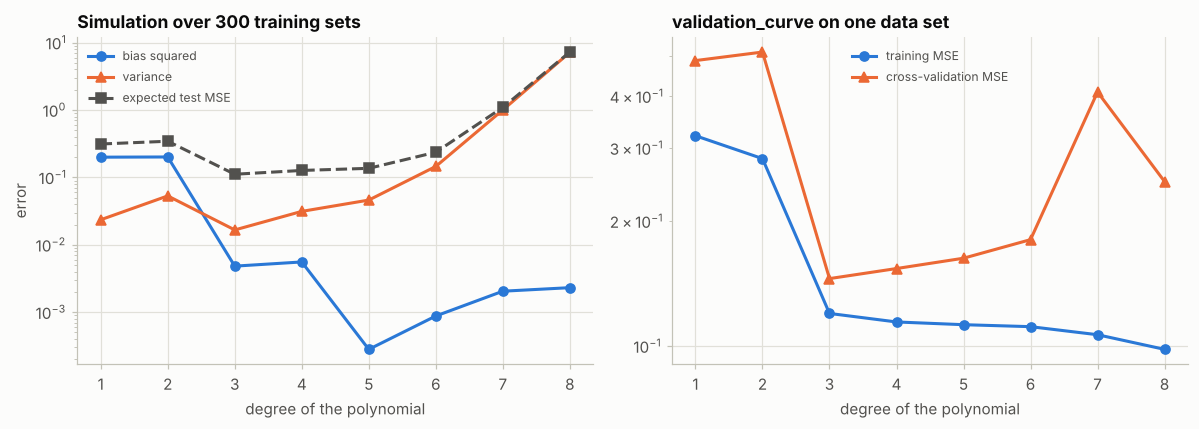

In [37]:
# EXTRA (e): bias, variance and the validation curve for the degree of a polynomial regression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline


def truth(x):
    return np.sin(2 * np.pi * x)


rng = np.random.default_rng(0)
noise_sd, degrees, n_sims, n_points = 0.3, list(range(1, 9)), 300, 30
abscissa = np.linspace(0, 1, 200)
predictions = {d: np.zeros((n_sims, len(abscissa))) for d in degrees}
for sim in range(n_sims):
    x_sim = rng.uniform(0, 1, n_points)
    y_sim = truth(x_sim) + rng.normal(0, noise_sd, n_points)
    for d in degrees:
        predictions[d][sim] = np.polyval(np.polyfit(x_sim, y_sim, d), abscissa)
decomposition = pd.DataFrame({
    "degree": degrees,
    "bias^2": [((predictions[d].mean(0) - truth(abscissa)) ** 2).mean() for d in degrees],
    "variance": [predictions[d].var(0).mean() for d in degrees],
})
decomposition["noise"] = noise_sd ** 2
decomposition["expected test MSE"] = decomposition[["bias^2", "variance", "noise"]].sum(axis=1)
print(decomposition.round(4).to_string(index=False))

x_one = rng.uniform(0, 1, n_points)
y_one = truth(x_one) + rng.normal(0, noise_sd, n_points)
poly = make_pipeline(PolynomialFeatures(include_bias=False), LinearRegression())
tr_poly, va_poly = validation_curve(poly, x_one.reshape(-1, 1), y_one, param_name="polynomialfeatures__degree", param_range=degrees, cv=5, scoring="neg_mean_squared_error")
print(f"\nvalidation curve of one data set of {n_points} points (MSE): training {np.round(-tr_poly.mean(1), 3).tolist()}")
print(f"                                                            cross-validation {np.round(-va_poly.mean(1), 3).tolist()}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(degrees, decomposition["bias^2"], color=PALETTE[0], marker="o", label="bias squared")
axes[0].plot(degrees, decomposition["variance"], color=PALETTE[1], marker="^", label="variance")
axes[0].plot(degrees, decomposition["expected test MSE"], color=INK_SOFT, marker="s", ls="--", label="expected test MSE")
axes[0].set_yscale("log")
axes[0].set_xlabel("degree of the polynomial")
axes[0].set_ylabel("error")
axes[0].set_title("Simulation over 300 training sets")
axes[0].legend(loc="upper left", fontsize=8)
axes[1].plot(degrees, -tr_poly.mean(1), color=PALETTE[0], marker="o", label="training MSE")
axes[1].plot(degrees, -va_poly.mean(1), color=PALETTE[1], marker="^", label="cross-validation MSE")
axes[1].set_yscale("log")
axes[1].set_xlabel("degree of the polynomial")
axes[1].set_title("validation_curve on one data set")
axes[1].legend(loc="upper center", fontsize=8)
plt.tight_layout()
plt.show()

**(f) What cross-validation cannot see.** A logistic regression is fitted on half of a data set (4,000 samples, 10 features); its 5-fold cross-validation accuracy and its accuracy on the other half are computed. Then the inputs of the other half are shifted: four of the ten features (the first four columns) are increased by `s` standard deviations of each column, as if the measurement had drifted after deployment.

In [38]:
# EXTRA (f): a shift of the inputs after "deployment" is invisible to cross-validation
X_shift, y_shift = make_classification(n_samples=4000, n_features=10, n_informative=8, n_redundant=2, random_state=5)
X_fit, X_after, y_fit, y_after = train_test_split(X_shift, y_shift, test_size=0.5, random_state=0)
fitted = LogisticRegression().fit(X_fit, y_fit)
print(f"5-fold cross-validation accuracy on the fitting half: {cross_val_score(LogisticRegression(), X_fit, y_fit, cv=5).mean():.3f}")
direction = np.zeros(10)
direction[:4] = X_fit[:, :4].std(axis=0)
rows = [{"shift of 4 features (standard deviations of each)": s, "accuracy on the second half": fitted.score(X_after + s * direction, y_after)} for s in [0, 0.5, 1.0, 1.5, 2.0]]
print(pd.DataFrame(rows).set_index("shift of 4 features (standard deviations of each)").round(3).to_string())

5-fold cross-validation accuracy on the fitting half: 0.843
                                                   accuracy on the second half
shift of 4 features (standard deviations of each)                             
0.0                                                                      0.850
0.5                                                                      0.824
1.0                                                                      0.786
1.5                                                                      0.722
2.0                                                                      0.658


**Analysis of the extras.**

* **(a)** The standard deviation of the validation score over the 5 folds (0.021 to 0.024 for `C` $\geq$ 0.1) is ten times the whole variation of the validation curve above `C=0.1` (0.890 to 0.892): as a rough rule, the values on the plateau cannot be told apart. The learning curve has a gap of 0.081 at 80 samples, 0.030 at 260 and 0.006 at 800.
* **(b)** With `shuffle=False`, the default and the book's call, `random_state` has **no effect** (largest difference between `random_state` 2024 and 7: 0.0000); with `shuffle=True` the results change (up to 0.080). The `random_state=2024` of the book's listing is decoration.
* **(c)** On a data set of 6,000 samples (generated with the same call, so a different problem from the book's 1,000-sample one) the validation score rises from 0.870 (80 samples) to 0.932 (260) and **levels off at 0.945 to 0.946 from 1,600 samples**; the gap falls from 0.098 to about zero ($\pm$ 0.002) from 1,600 on. The book's expectation that the curves "level off" with more data holds; the level (0.946) is that of this larger sample, not of the book's figure (0.892).
* **(d)** The logistic regression on the moons has a training score of 0.842 and a validation score of 0.842 (gap $-0.001$), already 0.840 at 80 samples: it is **high bias**, and more data cannot help. The unpruned decision tree has a training score of 1.000 and a validation score of 0.778 (80 samples) rising to 0.841 (1,600): a gap of **0.159** that closes slowly, which is **high variance**. The tree limited to depth 4 scores 0.880 and 0.863 (gap 0.017): the best validation score of the three.
* **(e)** The expected test error of the polynomial regression is lowest at **degree 3** (0.111: bias squared 0.005, variance 0.017, noise 0.09). Degrees 1 and 2 are dominated by bias (0.20), degrees 6 to 8 by variance (0.146, 1.00 and 7.16; the expected error at degree 8 is 7.25). The validation curve of one data set of 30 points has a similar U shape with its minimum at the same degree: the cross-validation MSE is lowest at degree 3 (0.145) and rises to 0.409 at degree 7 while the training MSE keeps falling (from 0.321 to 0.098); one data set is noisy (degree 8 is lower than degree 7).
* **(f)** The cross-validation accuracy of the fitting half is 0.843 and the accuracy on the second half 0.850. When four of the ten features of the second half are shifted by 0.5, 1, 1.5 and 2 of their standard deviations the accuracy falls to 0.824, 0.786, 0.722 and **0.658**, while the cross-validation estimate does not change at all: it measures the performance on data drawn from the sample's distribution.

---
## 6. Practical exercises in cross-validation and evaluation

*Book: pp. 328–329 (the code is in the official `Chapter 12 ... (Exercise Solutions).ipynb`).*

The three exercises give the steps and leave the code to the reader. The cells below are the official solutions, unchanged and in the book's order; the extras follow each solution. Two remarks on the official solution notebook: Exercise 3 uses `LogisticRegression` and the variables `X` and `y` that earlier cells defined (it only runs after Exercises 1 and 2), and Exercise 1 uses a data set with **no class weights**, unlike the recipes, so its classes are balanced.

### Exercise 1: Cross-validating a logistic regression model

Steps: load the libraries; load the dataset; cross-validate and collect metrics (k-fold cross-validation, several metrics).

In [39]:
# BOOK CODE (official solution, Exercise 1)
# Load libraries
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

# Load the dataset
X, y = make_classification(n_samples=500, n_features=10, random_state=2024)

# Cross-validate and collect metrics
model = LogisticRegression()
results = cross_validate(model, X, y, cv=5, scoring=["accuracy", "precision", "recall", "f1"])

for metric in ["test_accuracy", "test_precision", "test_recall", "test_f1"]:
    print(f"{metric}: {results[metric].mean():.3f}")

test_accuracy: 0.896
test_precision: 0.896
test_recall: 0.895
test_f1: 0.895


**Extras for Exercise 1.** (a) The class balance, the splitter that `cv=5` builds, the fold scores of each metric and a constant baseline. (b) A repeated stratified cross-validation (5 folds, 10 repeats) gives the spread of the accuracy over 50 test folds, and the spread of the 10 repeat means shows how much one 5-fold run can move.

In [40]:
# EXTRA: Exercise 1 - baseline, fold scores and a repeated cross-validation
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, check_cv, cross_val_score

print(f"class counts: {np.bincount(y).tolist()}; splitter built by cv=5: {check_cv(5, y, classifier=True)}")
print(pd.DataFrame({metric: results[f"test_{metric}"] for metric in ["accuracy", "precision", "recall", "f1"]}).round(3).rename_axis("fold").to_string())
print(f"accuracy of the constant 'most frequent class' baseline: {cross_val_score(DummyClassifier(strategy='most_frequent'), X, y, cv=5).mean():.3f}\n")

repeat_scores = cross_val_score(LogisticRegression(), X, y, cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0), scoring="accuracy")
per_repeat = repeat_scores.reshape(10, 5).mean(axis=1)
print(f"RepeatedStratifiedKFold(5, 10): mean accuracy {repeat_scores.mean():.3f}; sd over the 50 test folds {repeat_scores.std(ddof=1):.3f}")
print(f"the 10 repeat means (one 5-fold run each): {np.round(per_repeat, 3).tolist()}; sd {per_repeat.std(ddof=1):.4f}")

class counts: [253, 247]; splitter built by cv=5: StratifiedKFold(n_splits=5, random_state=None, shuffle=False)
      accuracy  precision  recall     f1
fold                                    
0         0.82      0.833   0.800  0.816
1         0.94      0.940   0.940  0.940
2         0.89      0.852   0.939  0.893
3         0.91      0.917   0.898  0.907
4         0.92      0.936   0.898  0.917
accuracy of the constant 'most frequent class' baseline: 0.506

RepeatedStratifiedKFold(5, 10): mean accuracy 0.895; sd over the 50 test folds 0.031
the 10 repeat means (one 5-fold run each): [0.9, 0.898, 0.9, 0.896, 0.9, 0.88, 0.89, 0.894, 0.898, 0.892]; sd 0.0063


### Exercise 2: Tuning hyperparameters with grid search

Steps: load the libraries; load and split the dataset; perform a grid search; evaluate on the test set.

In [41]:
# BOOK CODE (official solution, Exercise 2)
# Load libraries
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report

# Load and split the dataset
X, y = make_classification(n_samples=500, n_features=10, random_state=2024)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Perform grid search
param_grid = {"C": [0.1, 1, 10], "kernel": ["linear", "rbf"]}
grid = GridSearchCV(SVC(), param_grid, cv=5)
grid.fit(X_train, y_train)
print(f"Best parameters: {grid.best_params_}")

# Evaluate on the test set
y_pred = grid.predict(X_test)
print(classification_report(y_test, y_pred))

Best parameters: {'C': 0.1, 'kernel': 'rbf'}
              precision    recall  f1-score   support

           0       0.94      0.86      0.89        84
           1       0.84      0.92      0.88        66

    accuracy                           0.89       150
   macro avg       0.89      0.89      0.89       150
weighted avg       0.89      0.89      0.89       150



**Extras for Exercise 2.** (a) The candidates of the grid ranked by cross-validation score. (b) A nested cross-validation of the whole procedure (outer 5 folds over the 500 samples), with the parameters chosen in each outer fold, against the best score of the search on the training set and the test accuracy. (c) The 95% interval of the test accuracy, from the binomial standard error on 150 points.

In [42]:
# EXTRA: Exercise 2 - the ranking of the grid, nested CV of the procedure, and the error bar of the test accuracy
ranking = pd.DataFrame(grid.cv_results_)[["param_C", "param_kernel", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score")
print(ranking.rename(columns={"param_C": "C", "param_kernel": "kernel", "mean_test_score": "mean CV accuracy", "std_test_score": "sd over folds", "rank_test_score": "rank"}).round(4).to_string(index=False))

outer = cross_validate(GridSearchCV(SVC(), param_grid, cv=5), X, y, cv=5, return_estimator=True)
print(f"\nnested cross-validation of the whole procedure: accuracy {outer['test_score'].mean():.3f} (outer folds {np.round(outer['test_score'], 3).tolist()})")
print(f"parameters chosen in the 5 outer folds: {[e.best_params_ for e in outer['estimator']]}")
test_accuracy = grid.score(X_test, y_test)
standard_error = np.sqrt(test_accuracy * (1 - test_accuracy) / len(y_test))
print(f"\nbest_score_ of the search on the 350 training samples: {grid.best_score_:.3f}")
print(f"accuracy on the 150 test samples: {test_accuracy:.3f}; standard error {standard_error:.3f}; 95% interval {test_accuracy - 1.96 * standard_error:.3f} to {test_accuracy + 1.96 * standard_error:.3f}")

   C kernel  mean CV accuracy  sd over folds  rank
 0.1    rbf            0.8971         0.0190     1
 1.0    rbf            0.8971         0.0246     1
10.0 linear            0.8971         0.0246     1
 0.1 linear            0.8914         0.0232     4
 1.0 linear            0.8914         0.0214     4
10.0    rbf            0.8543         0.0277     6

nested cross-validation of the whole procedure: accuracy 0.912 (outer folds [0.83, 0.95, 0.92, 0.92, 0.94])
parameters chosen in the 5 outer folds: [{'C': 0.1, 'kernel': 'rbf'}, {'C': 0.1, 'kernel': 'rbf'}, {'C': 0.1, 'kernel': 'rbf'}, {'C': 0.1, 'kernel': 'rbf'}, {'C': 0.1, 'kernel': 'rbf'}]

best_score_ of the search on the 350 training samples: 0.897
accuracy on the 150 test samples: 0.887; standard error 0.026; 95% interval 0.836 to 0.937


### Exercise 3: Assessing model generalization with learning and validation curves

Steps: load the libraries; plot the learning curve; plot the validation curve. The solution reuses the data of Exercise 2 (500 samples) and a logistic regression.

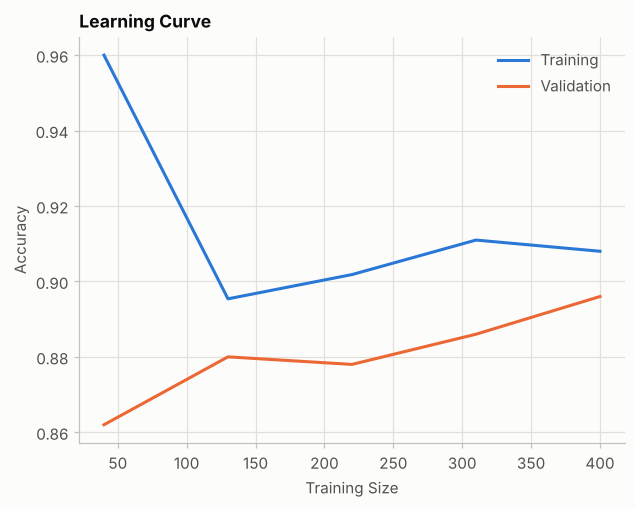

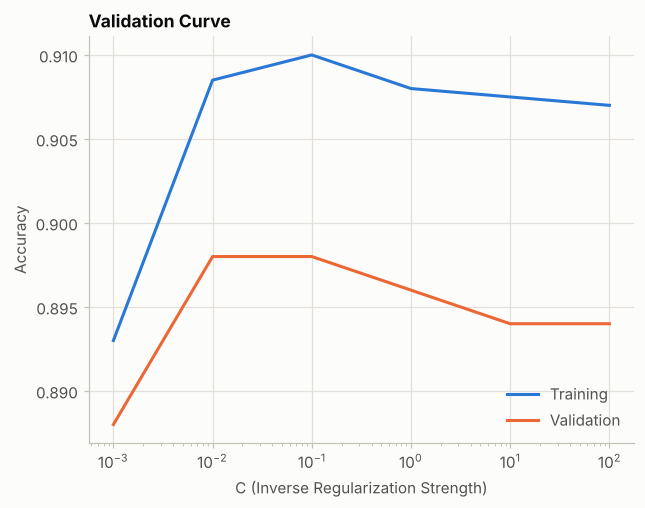

In [43]:
# BOOK CODE (official solution, Exercise 3)
# Load libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, validation_curve

# Plot the learning curve
train_sizes, train_scores, test_scores = learning_curve(
    LogisticRegression(), X, y, cv=5, scoring='accuracy', train_sizes=np.linspace(0.1, 1.0, 5), random_state=2024)

plt.plot(train_sizes, train_scores.mean(axis=1), label="Training")
plt.plot(train_sizes, test_scores.mean(axis=1), label="Validation")
plt.title("Learning Curve")
plt.xlabel("Training Size")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Plot the validation curve
param_range = np.logspace(-3, 2, 6)
train_scores, test_scores = validation_curve(
    LogisticRegression(), X, y, param_name="C", param_range=param_range,
    cv=5, scoring='accuracy')

plt.semilogx(param_range, train_scores.mean(axis=1), label="Training")
plt.semilogx(param_range, test_scores.mean(axis=1), label="Validation")
plt.title("Validation Curve")
plt.xlabel("C (Inverse Regularization Strength)")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

**Extras for Exercise 3.** The numbers behind the two curves of the solution, and the learning curve of a second model, an `SVC` with the default RBF kernel, on the same data: which of the two has the larger gap between training and validation scores?

In [44]:
# EXTRA: Exercise 3 - the values of the curves, and the learning curve of an SVC
sizes_lr, tr_lr, va_lr = learning_curve(LogisticRegression(), X, y, cv=5, scoring="accuracy", train_sizes=np.linspace(0.1, 1.0, 5))
sizes_svc, tr_svc, va_svc = learning_curve(SVC(), X, y, cv=5, scoring="accuracy", train_sizes=np.linspace(0.1, 1.0, 5))
print(pd.DataFrame({
    "training size": sizes_lr, "LogisticRegression: training": tr_lr.mean(1), "validation": va_lr.mean(1),
    "SVC (rbf): training": tr_svc.mean(1), "validation ": va_svc.mean(1),
}).round(3).to_string(index=False))
print(f"\ngap at the largest size: LogisticRegression {tr_lr.mean(1)[-1] - va_lr.mean(1)[-1]:+.3f}, SVC {tr_svc.mean(1)[-1] - va_svc.mean(1)[-1]:+.3f}")

tr_c, va_c = validation_curve(LogisticRegression(), X, y, param_name="C", param_range=param_range, cv=5, scoring="accuracy")
print("\nvalidation curve of the logistic regression:")
print(pd.DataFrame({"C": param_range, "training": tr_c.mean(1), "validation": va_c.mean(1), "sd of the validation score": va_c.std(1)}).round(3).to_string(index=False))

 training size  LogisticRegression: training  validation  SVC (rbf): training  validation 
            40                         0.960       0.862                0.980        0.862
           130                         0.895       0.880                0.958        0.884
           220                         0.902       0.878                0.946        0.896
           310                         0.911       0.886                0.944        0.906
           400                         0.908       0.896                0.946        0.906

gap at the largest size: LogisticRegression +0.012, SVC +0.040

validation curve of the logistic regression:
      C  training  validation  sd of the validation score
  0.001     0.893       0.888                       0.029
  0.010     0.908       0.898                       0.037
  0.100     0.910       0.898                       0.042
  1.000     0.908       0.896                       0.041
 10.000     0.908       0.894                       0.

**Analysis of the exercises.**

* **Exercise 1.** The solution prints accuracy 0.896, precision 0.896, recall 0.895 and $F_1$ 0.895 on 500 balanced samples (253 and 247). The five fold accuracies range from 0.82 to 0.94; a constant predictor scores 0.506. Over a repeated stratified 5-fold (10 repeats) the mean is 0.895 with a standard deviation of 0.031 over the 50 test folds, and the mean of one 5-fold run moves between 0.880 and 0.900 (standard deviation 0.0063): the 0.896 of the solution could as well have been 0.88 or 0.90.
* **Exercise 2.** The best parameters are `{'C': 0.1, 'kernel': 'rbf'}` and the test accuracy is 0.89 (0.887; precision 0.84 and recall 0.92 for class 1). **Three candidates tie for the first rank** at 0.8971 (`C=0.1` with `rbf`, `C=1` with `rbf` and `C=10` with `linear`); `GridSearchCV` keeps the first one, so the "best" parameters are partly arbitrary. A nested cross-validation of the whole procedure gives 0.912 (outer folds 0.83 to 0.95) and chooses `C=0.1` with `rbf` in all five outer folds. The `best_score_` on the training part is 0.897, the test accuracy 0.887 with a standard error of 0.026 (95% interval 0.836 to 0.937): the three numbers agree within their uncertainty.
* **Exercise 3.** The logistic regression has a training score of 0.960 (40 samples) falling to 0.908 (400) and a validation score rising from 0.862 to 0.896 (gap 0.012 at 400). The `SVC` with the RBF kernel has a training score of 0.946, a validation score of 0.906 and a larger gap (0.040): more variance, but a validation score 1 point higher. In the validation curve of the logistic regression the score is flat for `C` $\geq$ 0.01 (0.894 to 0.898) and the standard deviation over the folds (about 0.04) is ten times the variation of the curve.

---
## Hands-on exercises of the book, step by step

Every recipe of the chapter closes with a list of steps for the reader. This table records where this notebook performs each of them.

| Recipe | Steps proposed by the book | Where in this notebook |
|---|---|---|
| 1. Introduction | choose a classification dataset, explore the class balance, apply `KFold()` and `StratifiedKFold()`, train a model in each fold, evaluate, compare the consistency of both strategies | recipe 1 listings; extras 1(a) to 1(d) |
| 2. Advanced methods | regression dataset, `LeaveOneOut()` baseline, a grid for `Ridge`, `GridSearchCV()`, nested `cross_val_score()`, compare LOOCV and nested CV | recipe 2 listings; extras 2(a) to 2(c) |
| 3. Implementing CV | generate a dataset, baseline model, `cross_val_score()`, `cross_validate()`, `GridSearchCV()`, interpret the metrics | recipe 3 listings; extras 3(a) to 3(d) |
| 4. Model selection | split, grid search, randomized search with a continuous distribution, compare test performance, reflect on time and accuracy | recipe 4 listings; extras 4(a) to 4(f) |
| 5. Generalizability | `learning_curve()`, `validation_curve()`, plot both, interpret under- and overfitting, guide data collection or tuning | recipe 5 listings; extras 5(a) to 5(e) |

---
## Choosing a validation scheme: a decision guide

| Situation | Splitter | Notes from this chapter |
|---|---|---|
| Independent rows, regression | `KFold(5 or 10, shuffle=True)` | `cv=5` does not shuffle; shuffle if the rows are ordered |
| Classification, balanced classes, 500 rows or more | `StratifiedKFold(5 or 10)` (the default of `cv=5`) | stratification changes little here (1(a)) |
| Rare class or very small sample | `StratifiedKFold`, repeated (`RepeatedStratifiedKFold`) | a plain k-fold can leave a fold without any positive (1(d)); repeat to cut the partition noise |
| Very small sample, a cheap model | `LeaveOneOut`, or the closed form for linear smoothers | $n$ fits for no better RMSE than 5 or 10 folds (1(c)) |
| Several rows per subject, site or patient | `GroupKFold`, `StratifiedGroupKFold` | a random split leaks the subject (2(e)) |
| Ordered data (time) | `TimeSeriesSplit` | a random split leaks the neighbours (2(f)) |
| Hyperparameters to tune and a performance to report | nested CV, or a test set kept apart from the start | `best_score_` is optimistic (2(c), 4(f)) |
| Any preprocessing that learns from the data | a `Pipeline` inside the CV | a selection of features on all the data fakes an accuracy of 0.8 on noise (3(e)) |
| Imbalanced classes | `scoring='balanced_accuracy'`, `'f1'`, `'average_precision'` or `'roc_auc'` | always against a `DummyClassifier` baseline (3(b)) |
| One hyperparameter | a small grid | grid and random search tie; the plateau is wide (4(b), 4(c)) |
| Several hyperparameters | `RandomizedSearchCV` with log-uniform distributions | a third of the grid's budget costs about 0.6 points of test accuracy, within the noise (4(e)) |
| "Will it still work next quarter?" | monitoring after deployment (Chapter 13) | cross-validation cannot see a shift of the data (5(f)) |

---
## Chapter summary

Chapter 12 turns a model into a **measured** model. Cross-validation replaces a single, wasteful split by several: each observation is tested once and trained on $k-1$ times. The same machinery selects hyperparameters, and learning and validation curves show whether a model suffers from bias or from variance. All of it rests on three assumptions that the extras test one by one: the rows are independent, no information from the test fold reaches the training step, and the score that is reported was not also the score that was optimized.

### Key takeaways

1. **A cross-validation score is a noisy estimate of the average performance of a procedure.** On 500 rows its error bar is about two points; the book's difference of one point between `KFold` and `StratifiedKFold` is noise.
2. **Five or ten folds are enough.** In extra 1(c) two folds are pessimistic, while leave-one-out costs $n$ fits and does not reduce the error.
3. **`cv=5` is already stratified for a classifier.** Stratify explicitly, and repeat, when a class is rare or the sample is small.
4. **Always compare with a baseline and choose the metric from the application.** A constant predictor scores 0.70 accuracy on the 70/30 data; the metric also decides the winner of a search.
5. **Preprocessing that learns from data belongs inside a `Pipeline`.** Selecting features on all the data before cross-validating turned pure noise into an accuracy of 0.82.
6. **`best_score_` is not a test score.** The best of several noisy estimates is optimistic; use nested cross-validation or a test set kept apart, and use the test set once.
7. **Random search saves fits when there are several hyperparameters;** with one hyperparameter the book's random search used more fits than its grid.
8. **Respect the structure of the data.** Group the rows of a subject and respect the order of time, or the score is too optimistic by tens of points.
9. **Learning curves tell whether more data or more flexibility would help; validation curves show the effect of one hyperparameter.** Both are cross-validated and inherit its noise.
10. **Cross-validation cannot see what happens after deployment.** A shift of the data needs monitoring, which is the subject of Chapter 13.

### Book vs. library notes

* **Stratification in recipe 3.** The book says that the recipe does not use stratification and that the data is imbalanced. `cross_val_score(model, X, y, cv=5)` with a classifier uses `StratifiedKFold(5)`: every test fold holds 30 positives of 100.
* **Recipe 1.** The difference between 0.756 (`KFold`) and 0.766 (`StratifiedKFold`) comes from the random partition drawn by each splitter, not from stratification: the classes are balanced, and over 200 shuffles the two splitters have the same mean (0.770 and 0.771).
* **Recipe 2.** The target of `load_diabetes()` is quantitative (25 to 346), not "qualitative". The "Nested CV mean score: 0.480" is an $R^2$ (the default score of a regressor), not an MSE, and the "0.593 MSE" of the text appears nowhere in the code or in its output. The mean-prediction baseline has an MSE of about 5,982, so an $R^2$ of 0.48 is far better than guessing.
* **Recipe 4.** The randomized search of the book makes 50 fits, the grid 30; "fewer evaluations" holds only when the grid is larger than the number of draws. The text also reports the test accuracy of the randomized search only (0.940); the grid's winner scores 0.933, one test sample less.
* **Recipe 5.** `random_state` has no effect in `learning_curve` unless `shuffle=True`. In the validation curve of the book there is no overfitting at large `C`: the training and validation curves stay together and flat.
* **The missing recipe.** The introduction of the chapter lists "Model evaluation metrics overview", but the book has no such section (the table of contents does not list it either); the theory of recipe 3 covers it.
* **Exercises.** The solutions of Exercises 1 and 2 use data without class weights; Exercise 3 reuses `X`, `y` and `LogisticRegression` from earlier cells.
* **Library version.** All listings and the three official exercise solutions run on scikit-learn 1.9.1; the printed values of the chapter's listings are reproduced.

---
## References

1. Stone, M. (1974). Cross-validatory choice and assessment of statistical predictions. *Journal of the Royal Statistical Society, Series B, 36*(2), 111–147.
2. Kohavi, R. (1995). A study of cross-validation and bootstrap for accuracy estimation and model selection. *Proceedings of the 14th International Joint Conference on Artificial Intelligence (IJCAI)*, 1137–1143.
3. Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.). Springer. (Chapter 7)
4. Arlot, S., & Celisse, A. (2010). A survey of cross-validation procedures for model selection. *Statistics Surveys, 4*, 40–79.
5. Bengio, Y., & Grandvalet, Y. (2004). No unbiased estimator of the variance of K-fold cross-validation. *Journal of Machine Learning Research, 5*, 1089–1105.
6. Varoquaux, G. (2018). Cross-validation failure: small sample sizes lead to large error bars. *NeuroImage, 180*, 68–77.
7. Bates, S., Hastie, T., & Tibshirani, R. (2024). Cross-validation: what does it estimate and how well does it do it? *Journal of the American Statistical Association, 119*(546), 1434–1445.
8. Varma, S., & Simon, R. (2006). Bias in error estimation when using cross-validation for model selection. *BMC Bioinformatics, 7*, 91.
9. Cawley, G. C., & Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent selection bias in performance evaluation. *Journal of Machine Learning Research, 11*, 2079–2107.
10. Wainer, J., & Cawley, G. (2021). Nested cross-validation when selecting classifiers is overzealous for most practical applications. *Expert Systems with Applications, 182*, 115222.
11. Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281–305.
12. Jamieson, K., & Talwalkar, A. (2016). Non-stochastic best arm identification and hyperparameter optimization. *Proceedings of the 19th International Conference on Artificial Intelligence and Statistics (AISTATS)*, 240–248.
13. Breiman, L., Friedman, J., Olshen, R., & Stone, C. (1984). *Classification and Regression Trees*. Wadsworth.
14. Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929.
15. Bergmeir, C., & Benítez, J. M. (2012). On the use of cross-validation for time series predictor evaluation. *Information Sciences, 191*, 192–213.
16. Cerqueira, V., Torgo, L., & Mozetič, I. (2020). Evaluating time series forecasting models: an empirical study on performance estimation methods. *Machine Learning, 109*, 1997–2028.
17. Geman, S., Bienenstock, E., & Doursat, R. (1992). Neural networks and the bias/variance dilemma. *Neural Computation, 4*(1), 1–58.
18. Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), Article 15.
19. Raschka, S. (2018). Model evaluation, model selection, and algorithm selection in machine learning. arXiv:1811.12808.
20. scikit-learn documentation: [Cross-validation: evaluating estimator performance](https://scikit-learn.org/stable/modules/cross_validation.html) · [Tuning the hyper-parameters of an estimator](https://scikit-learn.org/stable/modules/grid_search.html) · [Metrics and scoring](https://scikit-learn.org/stable/modules/model_evaluation.html) · [Validation curves: plotting scores to evaluate models](https://scikit-learn.org/stable/modules/learning_curve.html)